# 진단 측정값으로 피마 인디언 여성의 당뇨병 여부를 예측할 수 있는가

## #1. 분석 개요

**분석 주제**

> 공개 데이터인 Kaggle Pima Indians Diabetes Database(원자료 768건, 결측 처리 후 724건)로 **21세 이상 피마 인디언 혈통 여성의 진단 측정값(임신횟수·포도당·혈압·BMI·당뇨 내력 가중치·나이 등)이 당뇨병 여부(`Outcome`)에 어떤 영향을 주는지** 확인한다.
> 원 데이터는 미국 국립 당뇨병·소화기·신장질환 연구소(NIDDK)가 제공한 것이며, 종속변수가 두 범주이므로 **로지스틱 회귀**를 사용한다. 결과는 인과가 아닌 **연관 관계**로 해석한다.
> 의료 데이터에서 0일 수 없는 값(포도당·혈압·피하지방·인슐린·BMI)이 0으로 입력되어 있어 **0값을 결측치로 처리**하는 것이 첫 과제다.

**분석 질문**

- **Q1.** 당뇨병 여부(`Outcome` = 1)에 가장 큰 영향을 주는 요인은 무엇인가?
- **Q2.** 0으로 입력된 값(사실상 결측)은 얼마나 되며, 어떤 변수를 제거하고 어떤 행을 제거했는가?
- **Q3.** 로짓 선형성 가정은 충족되는가? 위배된다면 처방으로 모형 성능이 얼마나 달라지는가?
- **Q4.** 약한 불균형 데이터(`0` 65.6% : `1` 34.4%)에서 최종 모형의 분류 성능은 어느 정도이며, 임계값은 어떻게 정해야 하는가?

**종속변수:** `Outcome` (0 / 1, 1 = 당뇨) → 분류 문제

**이번 노트북에서 수행하는 기법**

| 구분 | 내용 |
|---|---|
| 전처리 | 0값을 결측치로 변환, 결측률이 높은 `SkinThickness`(29.6%)·`Insulin`(48.7%) 변수 제거, 나머지 결측 행 제거(768건 → 724건), 종속변수 범주형 변환 |
| 이변량 분석 | 연속형 독립변수 6종 → 2집단 종속변수에 대한 **Mann-Whitney U 검정** |
| 다변량 분석 | 독립변수 간 상관분석, **VIF**로 다중공선성 점검 |
| 가정 검정 | **Box-Tidwell** 로짓 선형성 검정, **진단 → 처방(제곱항) → 검증 → 재진단 루프**, 계층 원칙, **Durbin-Watson** |
| 모형 비교 | 전처리를 하나씩 누적한 **체크포인트 6종**(가정 미반영 3종 + 가정 반영 3종) 비교 |
| 해석 | **오즈비(OR)**, **표준화계수(βstd)**, 혼동행렬·AUC, **임계값 조정** |


#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**


In [154]:
from helpers import *
from jussam import load_data
from IPython.display import display, Markdown
from pandas import DataFrame
import numpy as np

## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [155]:
origin = load_data('pima_indians_diabetes')
origin.head()

📚 이 데이터 세트는 원래 미국 국립 당뇨병·소화기·신장질환 연구소(National Institute of Diabetes and Digestive and Kidney Diseases)에서 제공한 것입니다. 이 데이터 세트의 목적은 데이터 세트에 포함된 특정 진단 측정값을 기반으로 환자의 당뇨병 여부를 진단적으로 예측하는 것입니다. 더 큰 데이터베이스에서 이러한 사례를 선택하는 데에는 몇 가지 제약 조건이 적용되었습니다. 특히, 여기에 포함된 모든 환자는 21세 이상의 피마 인디언 혈통을 가진 여성입니다. (출처: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

field                     type    description
------------------------  ------  --------------------------------
Pregnancies               연속형  임신횟수
Glucose                   연속형  포도당 부하 검사 수치
BloodPressure             연속형  혈압
SkinThickness             연속형  팔 삼두근 뒤쪽의 피하지방 측정값
Insulin                   연속형  혈청 인슐린
BMI                       연속형  체질량 지수
DiabetesPedigreeFunction  연속형  당뇨 내력 가중치 값
Age                       연속형  나이
Outcome                   명목형  당뇨여부(0 또는 1)



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


#### 2-2. 변수 정의서

In [156]:
column_means = {
    "Pregnancies":             "임신횟수",
    "Glucose":                  "포도당 부하 검사 수치",
    "BloodPressure":            "혈압",
    "SkinThickness":            "삼두근 뒤쪽의 피하지방 측정값",
    "Insulin":                  "혈청 인슐린",
    "BMI":                      " 체질량 지수",
    "DiabetesPedigreeFunction": "당뇨 내력 가중치 값",
    "Age":                      " 나이",
    "Outcome":                  "당뇨여부(0 또는 1)",
}

#### 2-3. 초기 가설

> 분석 전에 세운 가설이며, 판정은 **7-3. 질문별 답변과 가설 판정**에서 한다.

| 가설 | 내용 | 검증 위치 |
|---|---|---|
| H1 | 포도당 부하 검사 수치(`Glucose`)와 `BMI`가 높을수록 당뇨(`Outcome` = 1)일 오즈가 증가한다. | 4-3, 7-1 |
| H2 | 연속형 독립변수 6종 모두 단독으로 당뇨 여부와 관련이 있다(두 집단 간 차이가 있다). | 4-3 |
| H3 | 6종 모두 다변량 모형에서도 유의하다. | 5-2, 6-4 |
| H4 | 6종 모두 로짓 선형성 가정을 충족한다. | 6-1 |
| H5 | 최종 모형은 무조건 `0`이라고 답하는 모형(정확도 65.6%)보다 우수하다. | 4-2, 7-2 |


## #3. 품질 점검 및 기본 전처리

#### 3-1. 데이터 구조 점검

##### 자료형 확인

In [157]:
origin.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


##### 자료형 변환

- 로지스틱 회귀의 종속변수는 범주형 데이터이다.
  - 값의 종류만 확실히 구분할 수 있다면 숫자타입(int,float)도 상관 없음

In [158]:
df1 = my_qtcheck.set_type(origin, as_category=['Outcome'])

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Pregnancies               768 non-null    int64   
 1   Glucose                   768 non-null    int64   
 2   BloodPressure             768 non-null    int64   
 3   SkinThickness             768 non-null    int64   
 4   Insulin                   768 non-null    int64   
 5   BMI                       768 non-null    float64 
 6   DiabetesPedigreeFunction  768 non-null    float64 
 7   Age                       768 non-null    int64   
 8   Outcome                   768 non-null    category
dtypes: category(1), float64(2), int64(6)
memory usage: 48.9 KB


#### 3-2. 데이터 품질 점검

##### 데이터 중복 점검

In [159]:
df2 = my_qtcheck.check_duplicates(df1)
df2.head()

중복된 행의 수: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


##### 결측치 점검

In [160]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,0,0.000
BloodPressure,0,0.000
SkinThickness,0,0.000
Insulin,0,0.000
BMI,0,0.000
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


> 중복도 결측치도 없다.

#### 3-3. 기술통계량

##### 명목형 변수의 기술 통계량

In [161]:
cat_desc = my_qtcheck.categorical_summary(df2)
cat_desc

컬럼 'Outcome'의 value_counts( ):


,count
Outcome,
0,500
1,268


,Outcome
count,768
unique,2
top,0
freq,500


##### 연속형 변수의 기술 통계량

In [162]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
Pregnancies,768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000,0.282,diff,5.000,13.500,-6.500,4,0.005,0,0.000,4,0.005,0.902,right tail,0.159,leptokurtic,log1p
Glucose,768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000,0.033,similar,41.250,202.125,37.125,0,0.000,5,0.007,5,0.007,0.174,symmetric,0.641,leptokurtic,none
BloodPressure,768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000,0.040,similar,18.000,107.000,35.000,7,0.009,38,0.049,45,0.059,-1.844,left tail,5.180,leptokurtic,reverse_log1p
SkinThickness,768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000,0.107,diff,32.000,80.000,-48.000,1,0.001,0,0.000,1,0.001,0.109,symmetric,-0.520,platykurtic,none
Insulin,768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000,1.616,large_diff,127.250,318.125,-190.875,34,0.044,0,0.000,34,0.044,2.272,right tail,7.214,leptokurtic,log1p
BMI,768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100,0.000,similar,9.300,50.550,13.350,8,0.010,11,0.014,19,0.025,-0.429,symmetric,3.290,leptokurtic,none
DiabetesPedigreeFunction,768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420,0.267,diff,0.382,1.200,-0.330,29,0.038,0,0.000,29,0.038,1.920,right tail,5.595,leptokurtic,log
Age,768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000,0.146,diff,17.000,66.500,-1.500,9,0.012,0,0.000,9,0.012,1.130,right tail,0.643,leptokurtic,log


> 최소값이 0인 항목이 다수 발견된다. 의료 데이터에서 수치가 0일 수는 없기 때문에 이 항목을 결측치로 봐야 한다.

#### 3-4. 0값을 결측치로 변경후 결측치 재확인

- 다음의 항목은 0값이 존재할 수 없다.
  - Glucose                   연속형  포도당 부하 검사 수치
  - BloodPressure             연속형  혈압
  - SkinThickness             연속형  팔 삼두근 뒤쪽의 피하지방 측정값
  - Insulin                   연속형  혈청 인슐린
  - BMI                       연속형  체질량 지수
- 하지만 다음의 변수는 해당사항이 없다.
  - 임신횟수(Pregnancies)는 0이 가능한 변수이므로 **반드시 처리 대상에서 제외**해야 한다.
  - 나이(Age)와 당뇨 내력 가중치(DiabetesPedigreeFunction)는 0이 포함되어 있지 않아 처리하더라도 값이 변하지 않는다.

In [163]:
df3 = df2.copy()

# 연속형 컬럼의 이름을 가져와서 반복 순환
for col in df3.select_dtypes(include='number').columns:
    # 컬럼 이름 0값을 포함하는 컬럼인 경우만 처리
    if col not in ['Pregnancies', 'Age']:
        df3[col] = np.where(df3[col] > 0, df3[col], np.nan)

my_qtcheck.check_missing_values(df3)

,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,5,0.651
BloodPressure,35,4.557
SkinThickness,227,29.557
Insulin,374,48.698
BMI,11,1.432
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


#### 3-5. 결측치 제거

- Glucose(0.7%), BloodPressure(4.6%), BMI(1.4%): 결측치가 5% 미만이므로 **해당 행을 제거**해도 안전하다.
- SkinThickness(29.6%), Insulin(48.7%): 결측치 비율이 과도하게 높으므로 **변수 자체를 제거**한다.
  - 절반 가까이를 중앙값 하나로 대체하면 분산이 인위적으로 줄어 변수가 가진 정보가 사라진다.
- 세 변수의 결측 행을 합치면 **44건(5.7%)이 제거되어 768건 → 724건**이 된다.

In [164]:
# 결측치 비중이 과도하게 높은 컬럼 제거
df4 = df3.drop(columns=['SkinThickness', 'Insulin'])

# 컬럼이 제거된 데이터프레임에서 결측치 비중이 낮은 변수에 대해 행 단위 제거
df4 = df4.dropna().reset_index(drop=True)

# 결측치 제거 결과 확인
my_qtcheck.check_missing_values(df4)

,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,0,0.000
BloodPressure,0,0.000
BMI,0,0.000
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


#### 3-6. 기술통계량 재확인

- 값이 변경되었으므로 기술 통계량을 다시 산정해야 한다.

In [165]:
num_desc = my_qtcheck.numerical_summary(df4)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
Pregnancies,724.000,3.866,3.363,0.000,1.000,3.000,6.000,17.000,0.289,diff,5.000,13.500,-6.500,4,0.006,0,0.000,4,0.006,0.905,right tail,0.178,leptokurtic,log1p
Glucose,724.000,121.883,30.750,44.000,99.750,117.000,142.000,199.000,0.042,similar,42.250,205.375,36.375,0,0.000,0,0.000,0,0.000,0.527,right tail,-0.304,platykurtic,none
BloodPressure,724.000,72.401,12.380,24.000,64.000,72.000,80.000,122.000,0.006,similar,16.000,104.000,40.000,10,0.014,4,0.006,14,0.019,0.138,symmetric,0.923,leptokurtic,none
BMI,724.000,32.467,6.889,18.200,27.500,32.400,36.600,67.100,0.002,similar,9.100,50.250,13.850,7,0.010,0,0.000,7,0.010,0.598,right tail,0.936,leptokurtic,log
DiabetesPedigreeFunction,724.000,0.475,0.332,0.078,0.245,0.379,0.627,2.420,0.253,diff,0.382,1.201,-0.329,28,0.039,0,0.000,28,0.039,1.922,right tail,5.626,leptokurtic,log
Age,724.000,33.351,11.765,21.000,24.000,29.000,41.000,81.000,0.150,diff,17.000,66.500,-1.500,7,0.010,0,0.000,7,0.010,1.089,right tail,0.501,leptokurtic,log


> **BloodPressure 최솟값 24**: 이완기 혈압 24mmHg는 생존이 어려운 수치이지만 여기서는 0만 결측으로 보고 나머지는 실측으로 인정하여 진행한다.

## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 변수 유형 분류와 EDA 범위

##### 변수 유형 분류

In [166]:
target = "Outcome"    # 종속변수
target_is_continuous = False    # 종속변수 연속형 여부  --> 로지스틱이므로 False
nominal_cols = my_qtcheck.get_categorical_column_names(df4) # 명목형 변수
continuous_cols = my_qtcheck.get_number_column_names(df4)   # 연속형 변수

if target_is_continuous:
    continuous_cols.remove(target)  # 연속형 변수 이름에서 종속변수 항목 제거
else:
    nominal_cols.remove(target)     # 명목형 변수 이름에서 종속변수 항목 제거

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Outcome
종속변수 유형: 명목형
명목형   : []
연속형   : ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction', 'Age']


##### 서열척도 적용 (필요에 따라 수행)

- 명목형 범주에 순서가 있다면 순서를 지정한다. (도메인 지식이 필요한 부분)
- 이 데이터셋에는 **서열척도 대상이 없다.** 코드는 다른 데이터셋에 그대로 옮겨 쓸 수 있도록 남겨 둔다.

In [167]:
# 서열척도를 적용할 변수와 순서를 정의한다. (낮은 등급 → 높은 등급)
# -> 도메인 지식이 필요한 부분이다.
# -> 서열척도 대상이 없는 데이터셋이라면 빈 딕셔너리로 둔다.
ordinal_map = {}

# 정의된 내용에 따라 순서를 재지정한다.
# -> 데이터셋에 없는 컬럼은 건너뛰므로 다른 데이터셋에서도 오류가 나지 않는다.
df = df4.copy()

for col, order in ordinal_map.items():
    if col in df.columns:
        print(f"'{col}' 컬럼 순서 재지정 : {order}")
        df[col] = df[col].cat.reorder_categories(order, ordered=True)

##### EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | 연속형 독립변수 6종 → `Outcome` | ✅ **적용** | 이 데이터의 핵심 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- 종속변수 `Outcome`가 **명목형 2집단**이므로 4~6행만 후보가 되고, 그 중 독립변수가 실제로 존재하는 **T검정**만 수행된다.
- **주의** — 종속변수가 명목형이면 **상관분석(피어슨·스피어만)을 쓸 수 없다.**
  상관계수는 두 변수가 모두 연속형일 때 정의되는 지표이기 때문이다.

#### 4-2. 분포 확인 (단변량 분석)

##### 명목형 종속변수에 대한 단변량 분석

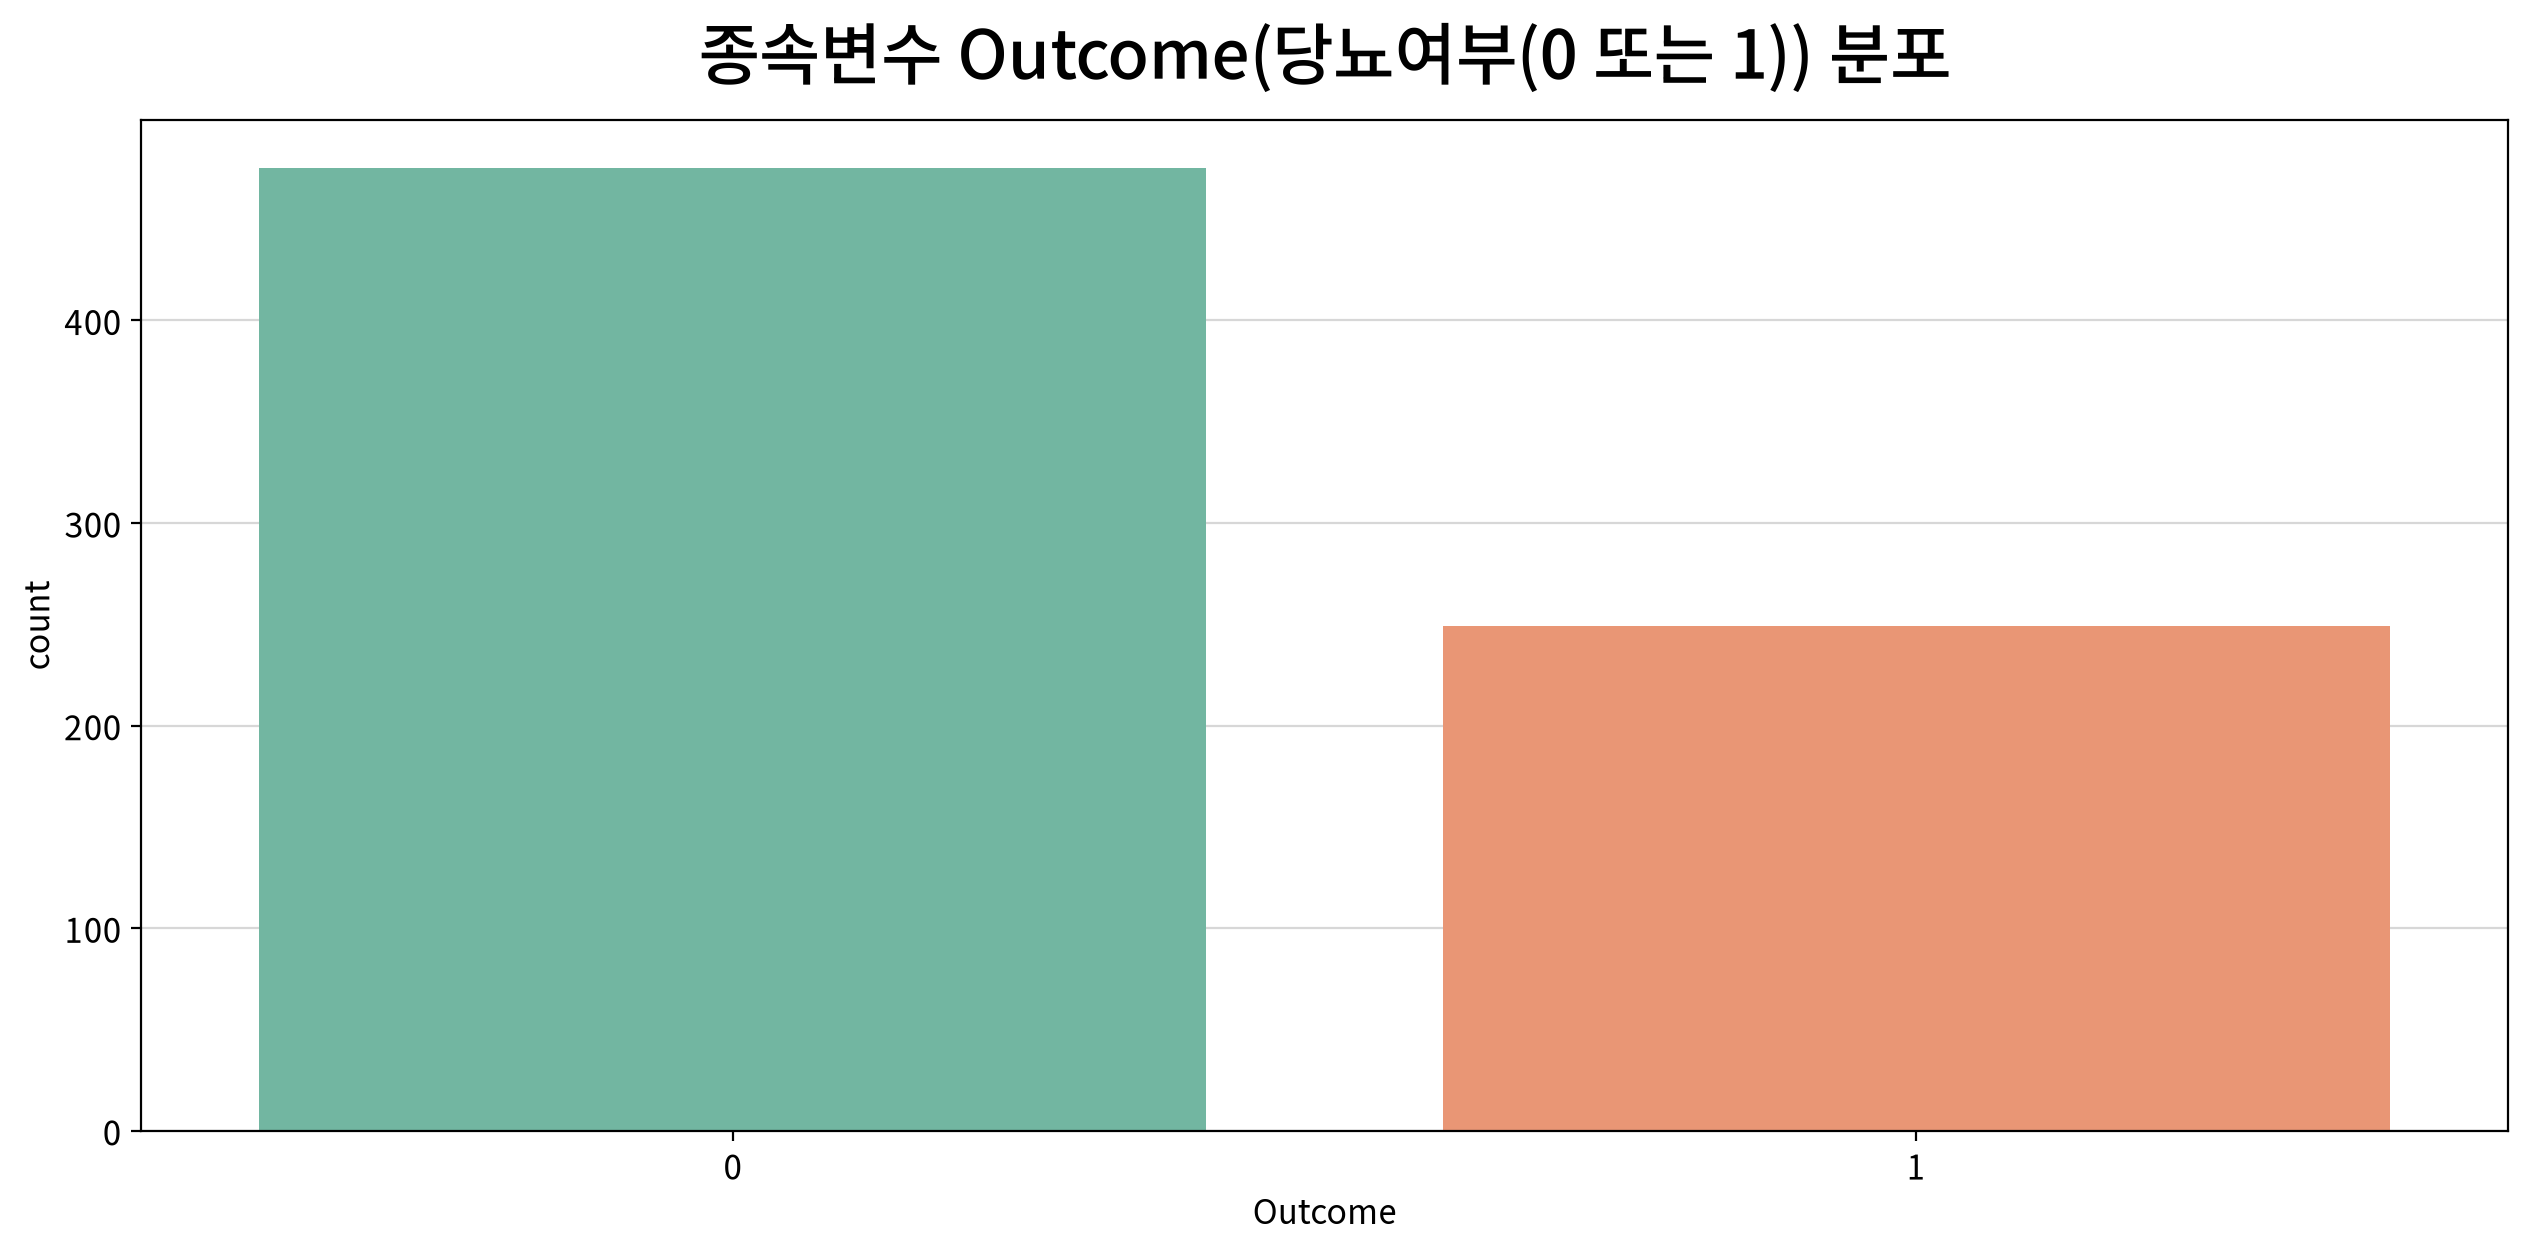

,count,unique,top,freq
Outcome,768,2,0,500


,빈도,비율
Outcome,,
0,475,0.656
1,249,0.344


In [168]:
# 명목형 분포는 카운트 플롯으로 처리한다.
my_plot.countplot(data=df, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

# 명목형 기술통계량
display(cat_desc[[target]].T)

# 추가적으로 빈도표 생성
freq = df[target].value_counts().rename("빈도").to_frame()
# value_counts(normalize=True)
# --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
freq["비율"] = df[target].value_counts(normalize=True)
display(freq)

#### 💡 인사이트

| 점검 항목 | `Outcome` 관찰값 |
|---|---|
| 범주 수 | 2 (`0` / `1`) → **이분형** 이므로 로지스틱 회귀 적용 가능 |
| 최빈 범주 | `0` 475건 (65.6%) |
| 최소 범주 | `1` 249건 (34.4%) |
| 균형 여부 | **약한 불균형** (65 : 34) |

  - 무조건 `0`이라고만 답하는 게으른 모형의 정확도는 **65.6%** 이다.
  - 즉 정확도 65.6%가 이 데이터의 **바닥값(baseline)** 이고, 모형은 그보다 얼마나 올라가는지로 평가한다.
  - 65 : 34 정도의 불균형은 심각한 수준은 아니라 별도의 리샘플링 없이 진행하지만,
  **정확도 하나만 보지 말고 재현율·정밀도·AUC를 함께 확인**해야 한다.

##### 연속형 독립변수에 대한 단변량 분석

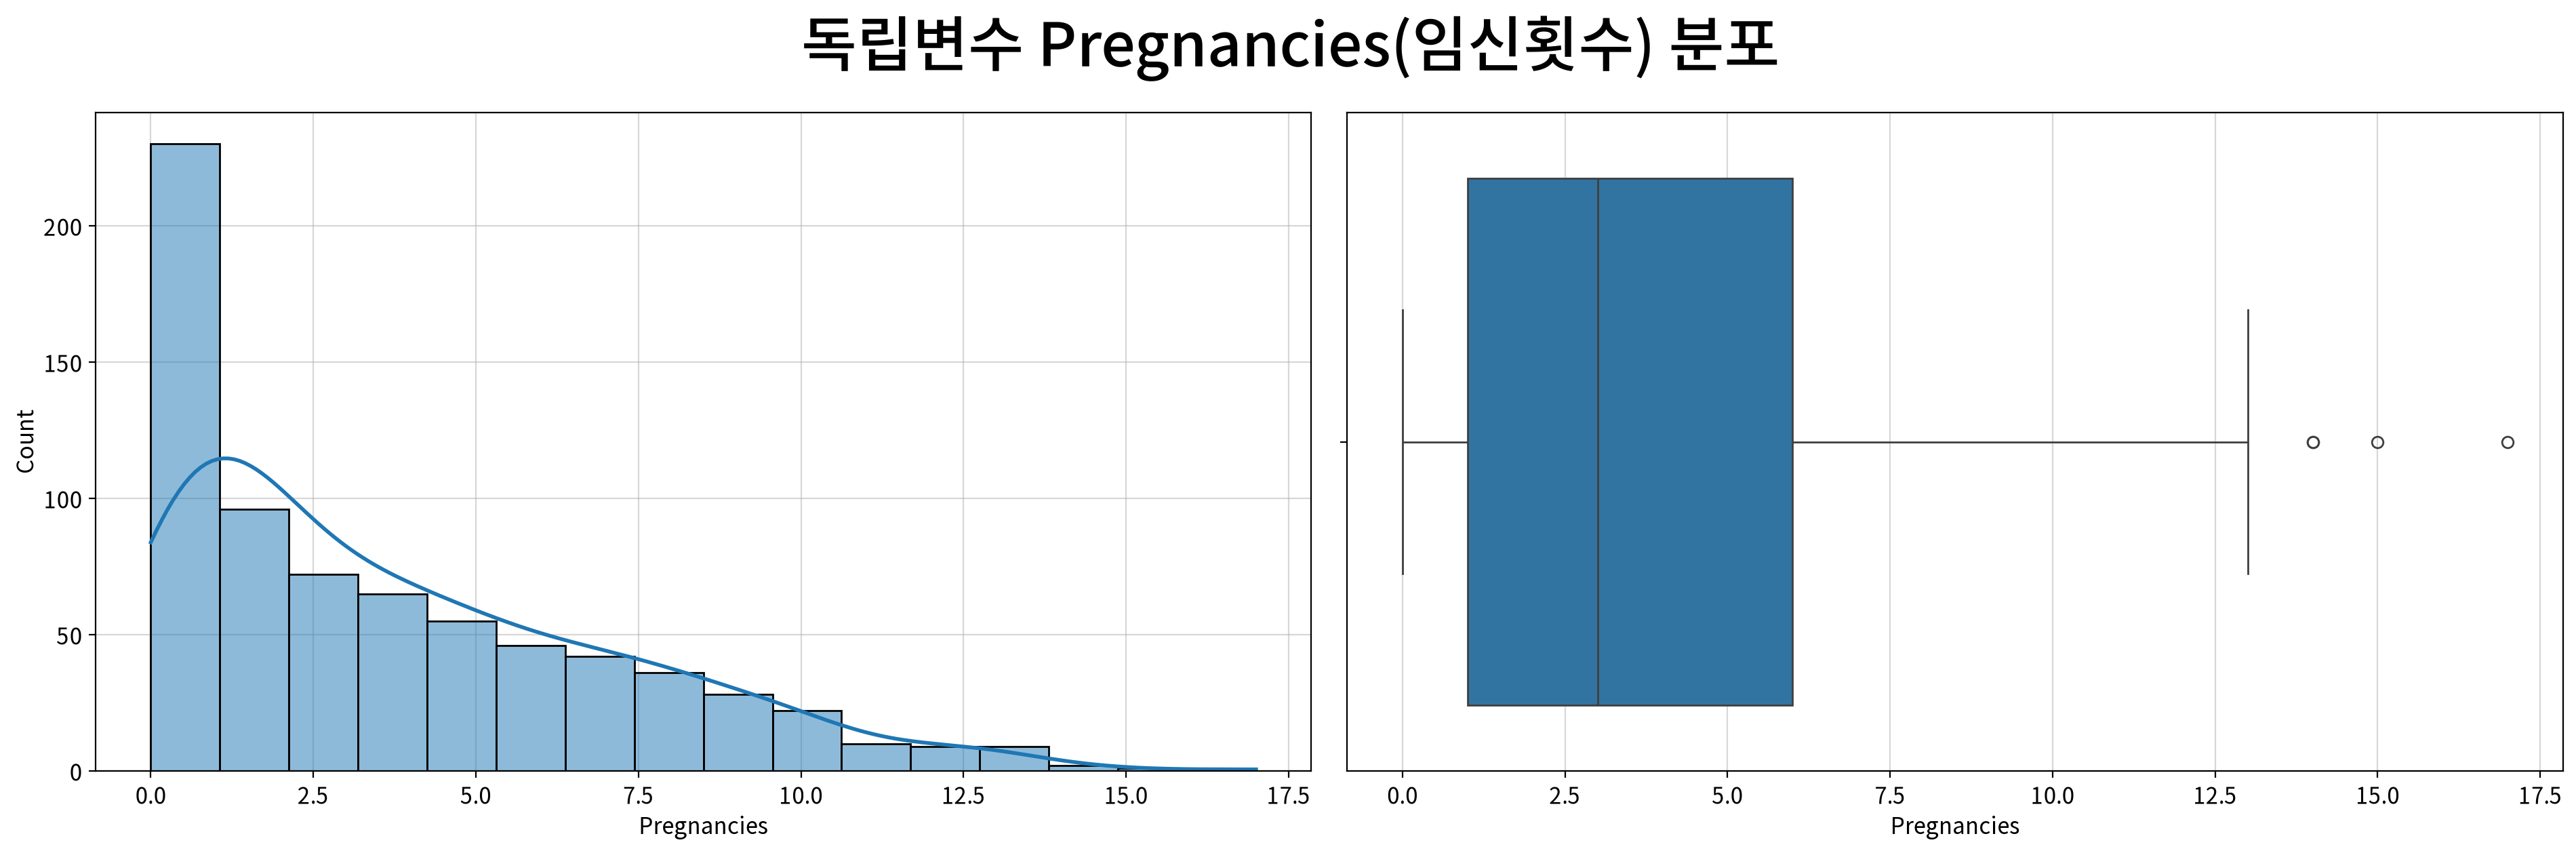

,Pregnancies
count,724.000
mean,3.866
std,3.363
min,0.000
25%,1.000
50%,3.000
75%,6.000
max,17.000
rel_diff,0.289
rdiff_flag,diff


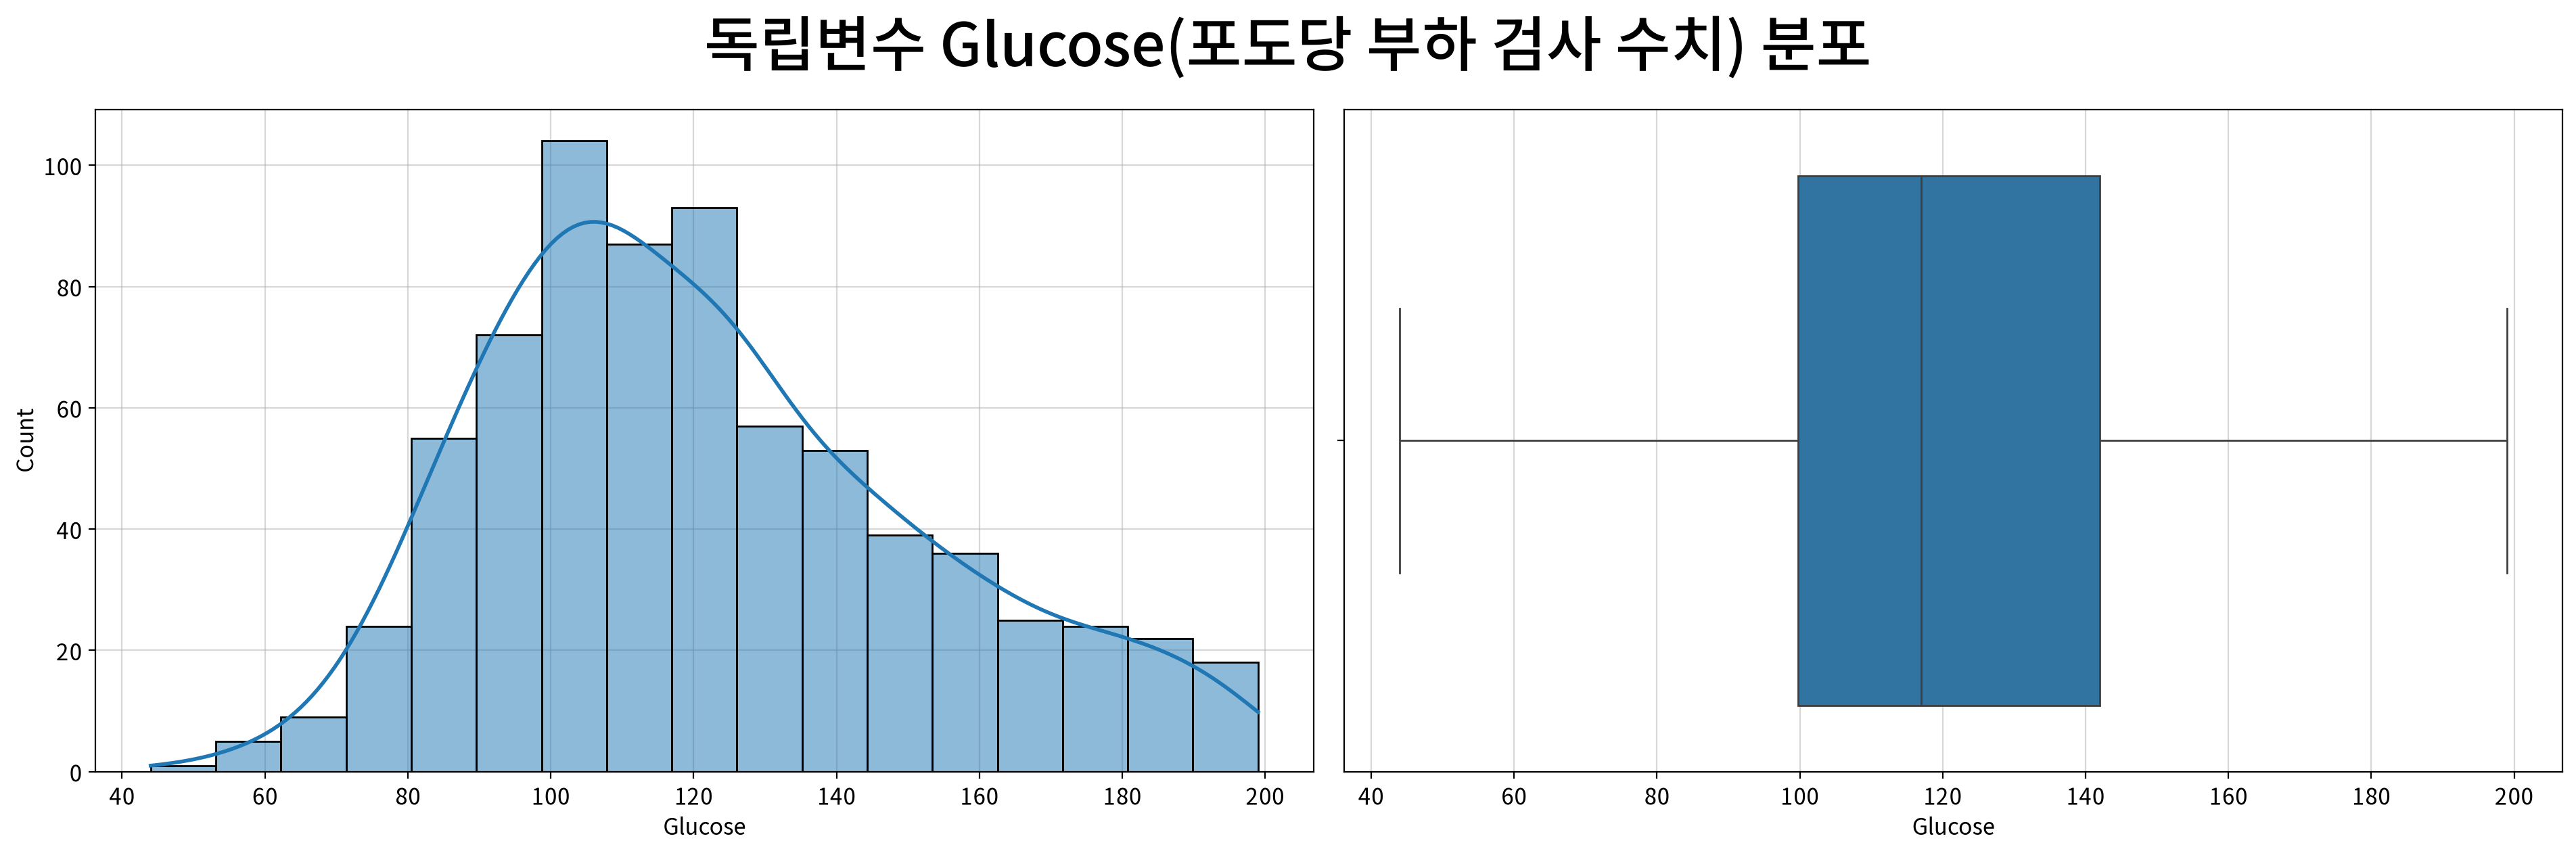

,Glucose
count,724.000
mean,121.883
std,30.750
min,44.000
25%,99.750
50%,117.000
75%,142.000
max,199.000
rel_diff,0.042
rdiff_flag,similar


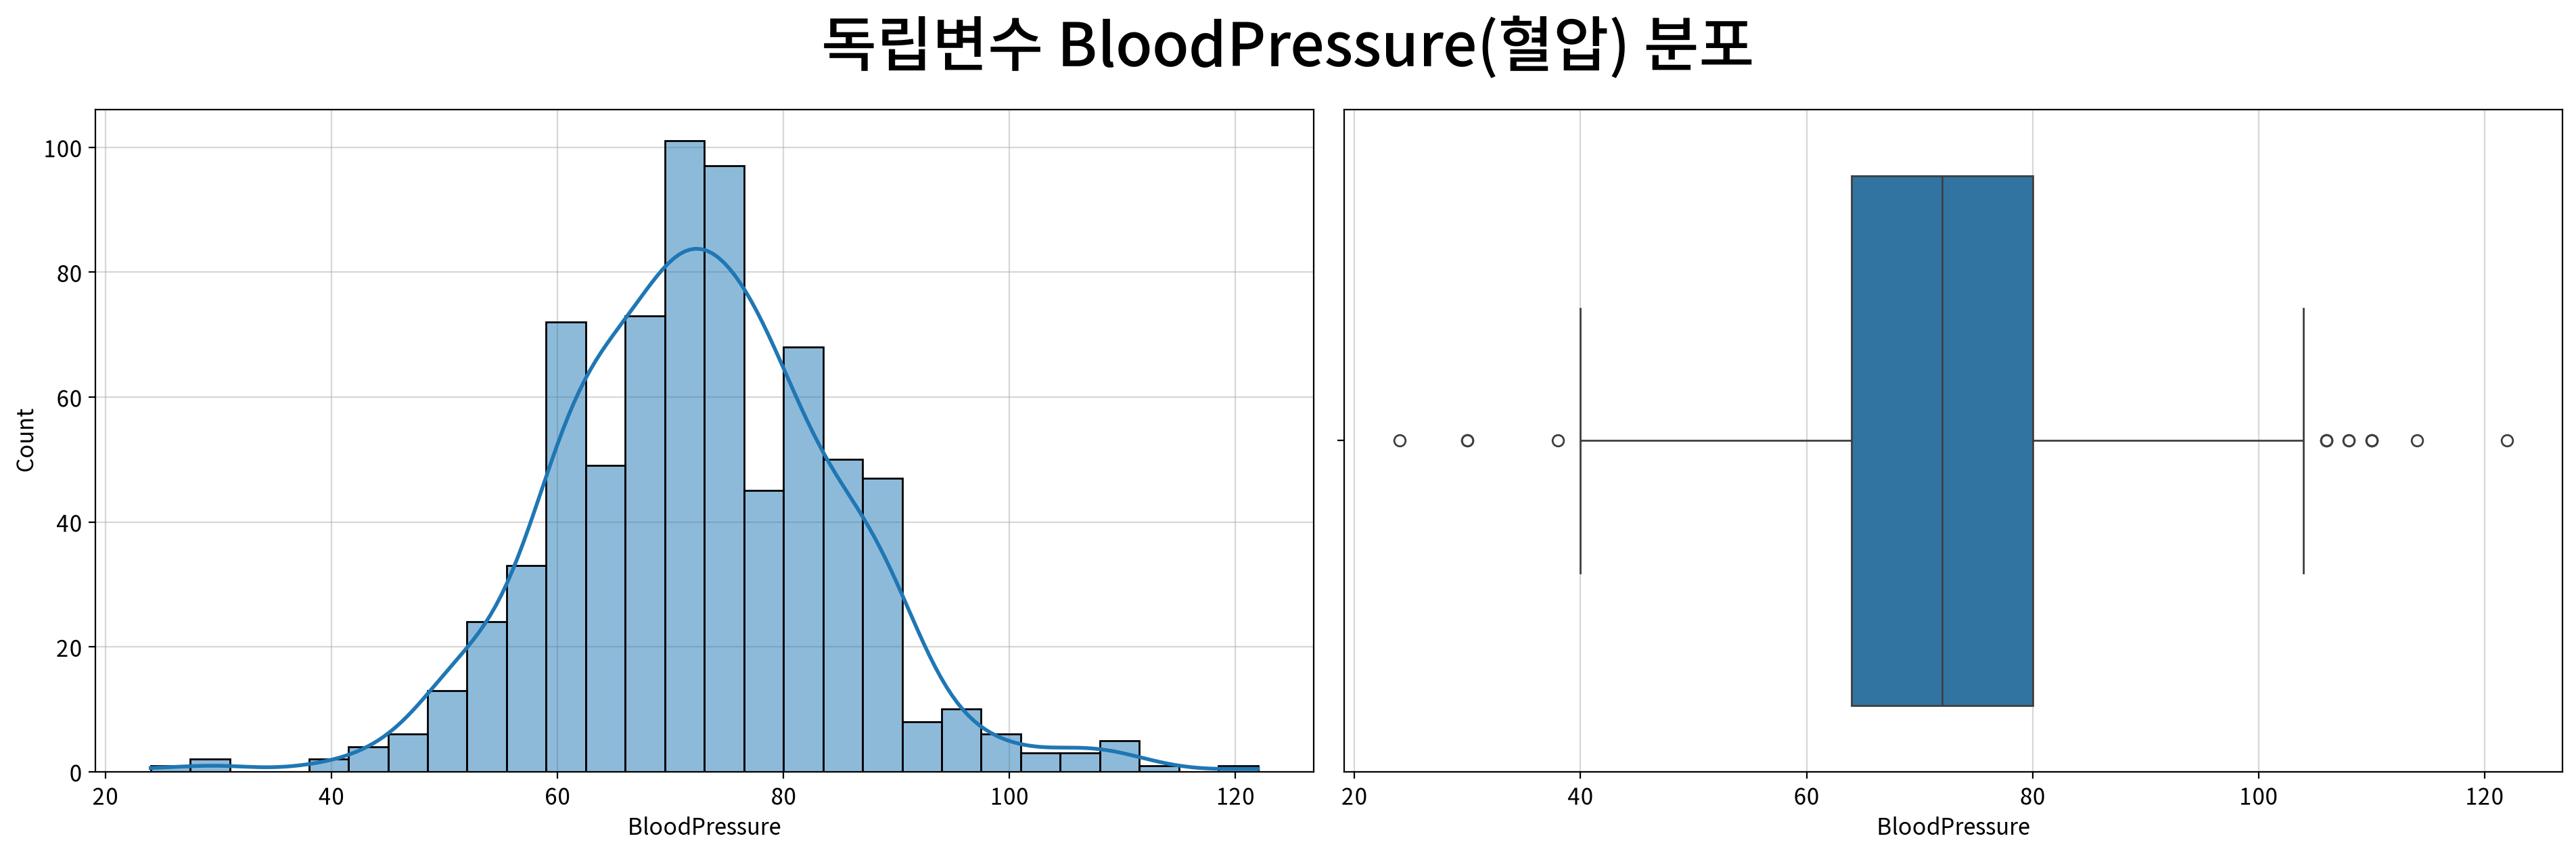

,BloodPressure
count,724.000
mean,72.401
std,12.380
min,24.000
25%,64.000
50%,72.000
75%,80.000
max,122.000
rel_diff,0.006
rdiff_flag,similar


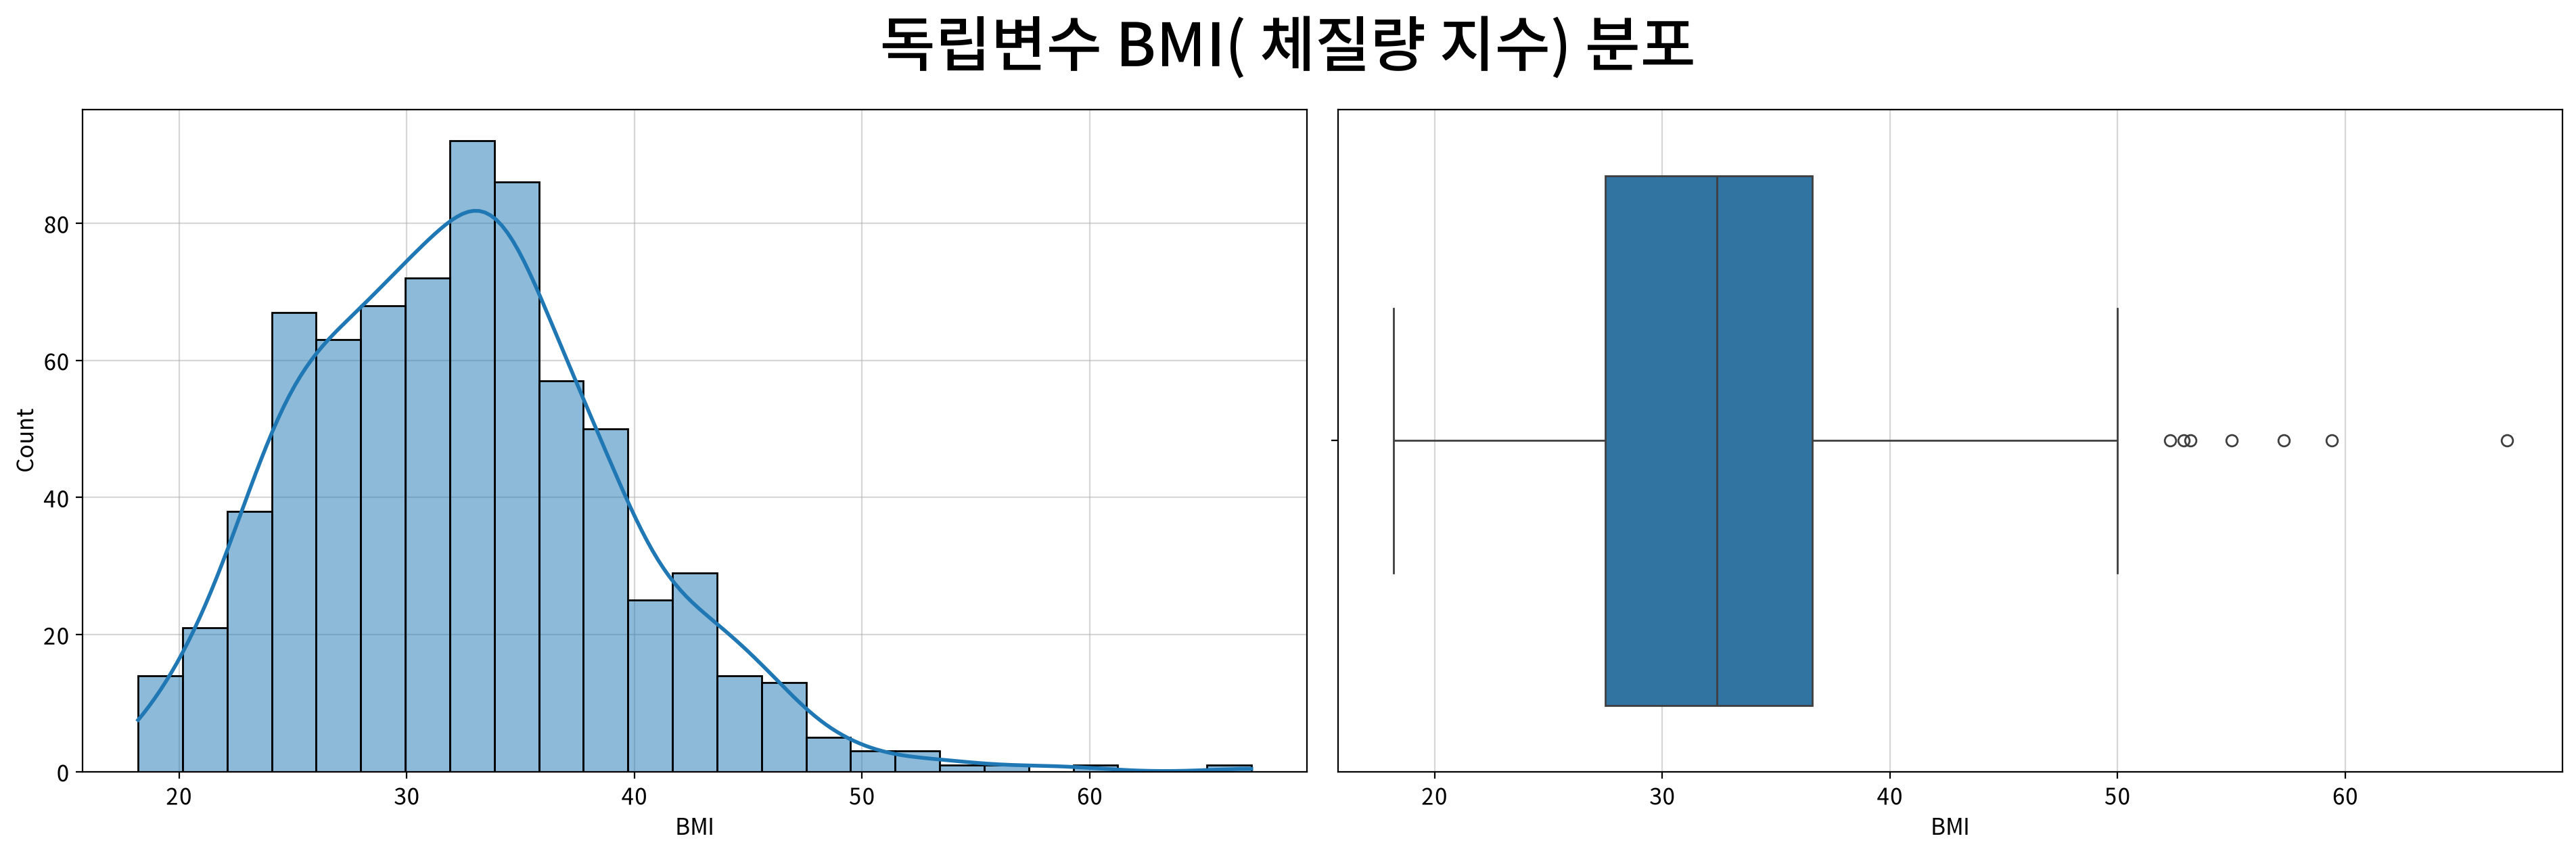

,BMI
count,724.000
mean,32.467
std,6.889
min,18.200
25%,27.500
50%,32.400
75%,36.600
max,67.100
rel_diff,0.002
rdiff_flag,similar


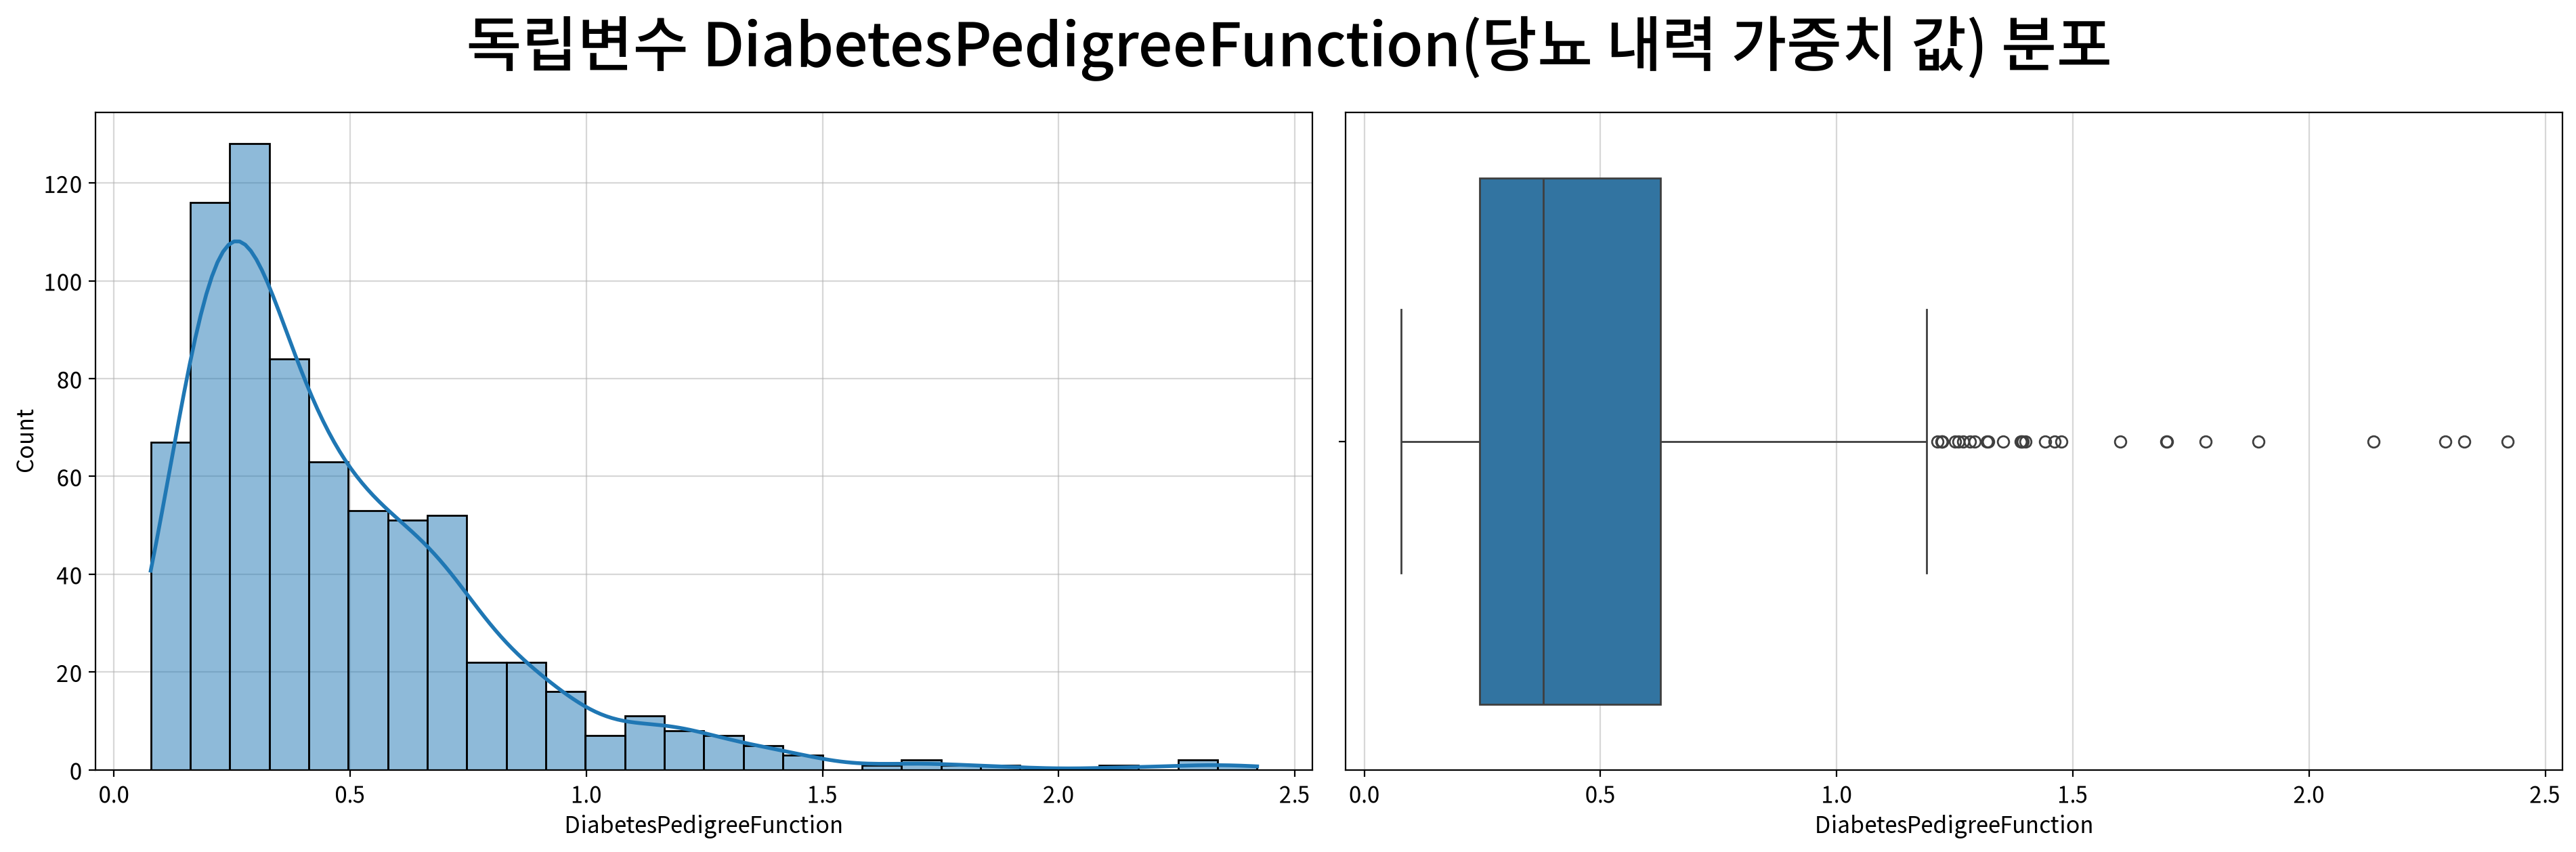

,DiabetesPedigreeFunction
count,724.000
mean,0.475
std,0.332
min,0.078
25%,0.245
50%,0.379
75%,0.627
max,2.420
rel_diff,0.253
rdiff_flag,diff


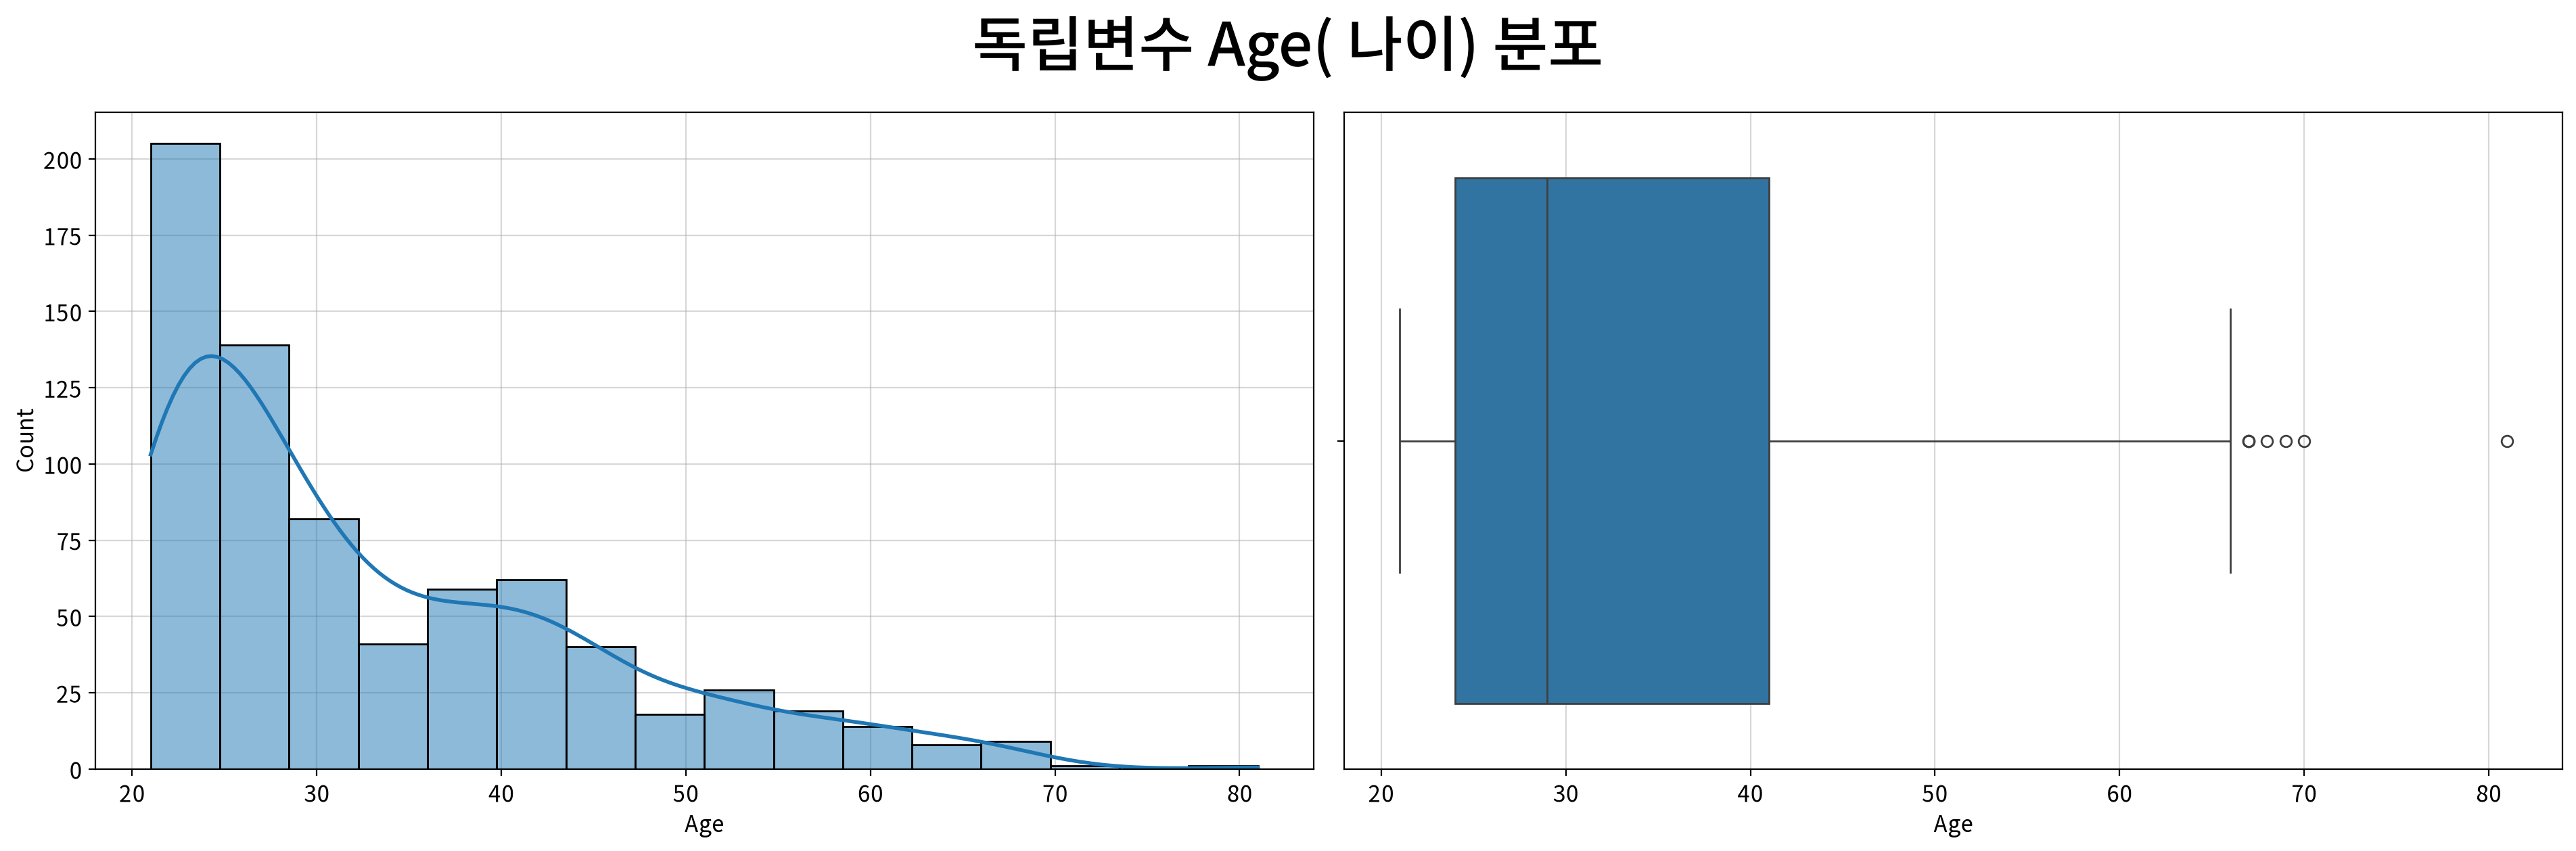

,Age
count,724.000
mean,33.351
std,11.765
min,21.000
25%,24.000
50%,29.000
75%,41.000
max,81.000
rel_diff,0.150
rdiff_flag,diff


In [169]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

#### 💡 인사이트

| 변수 | 분포 모양(왜도) | 봉우리 수 | 이상치 | `log_need` 판정 |
|---|---|---|---|---|
| `Pregnancies` | 오른쪽 꼬리 (+0.91) | 단봉 | 4건 (0.6%) | log1p |
| `Glucose` | 거의 대칭 (+0.53) | 단봉 | 0건 (0%) | 변환 불필요 |
| `BloodPressure` | 대칭 (+0.14) | 단봉 | 14건 (1.9%) | 변환 불필요 |
| `BMI` | 약한 오른쪽 꼬리 (+0.60) | 단봉 | 7건 (1.0%) | log |
| `DiabetesPedigreeFunction` | 오른쪽 꼬리 (+1.92) | 단봉 | 28건 (3.9%) | log |
| `Age` | 오른쪽 꼬리 (+1.09) | 단봉 | 7건 (1.0%) | log |

- `log_need`는 왜도만 보고 제안한 값이며, 로지스틱 회귀에서는 로그변환 여부를 **로짓 선형성 검정**이 결정한다(바로 아래 "이 데이터에서 제외되는 전처리" 참고).


##### 이 데이터에서 제외되는 전처리

- 데이터셋 특성에 따른 제외
  - **범주형 독립변수의 라벨링 및 더미변수 처리**
    - 이 데이터셋에는 범주형 독립변수가 없기 때문에  해당되지 않는다.
  - **이상치 대체**
    - 의료 데이터에 대한 이상치는 실제 측정된 수치라 판단하여 처리하지 않기로 결정
- 로지스틱 회귀 특성에 따른 제외
  - **로그변환**
    - 로지스틱 회귀는 **독립변수의 정규성을 가정하지 않으므로**, 선형회귀와 달리 왜도가 크다는 이유만으로 로그변환을 하지 않는다.
    - 변환이 필요한 경우는 로짓 선형성이 깨졌을 때이며, 변환 여부는 **로짓 선형성 검정**이 결정한다.

#### 4-3. 변수 간 관계 (이변량 분석)

##### T-Test (x: 연속형 독립변수 → y: 2집단 명목형 종속변수)

#### ▶︎ Pregnancies(임신횟수) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    44489.000    0.000         True  0 ≠ 1
                    less         44489.000    0.000         True  0 < 1
                    greater      44489.000    1.000        False  0 ≤ 1

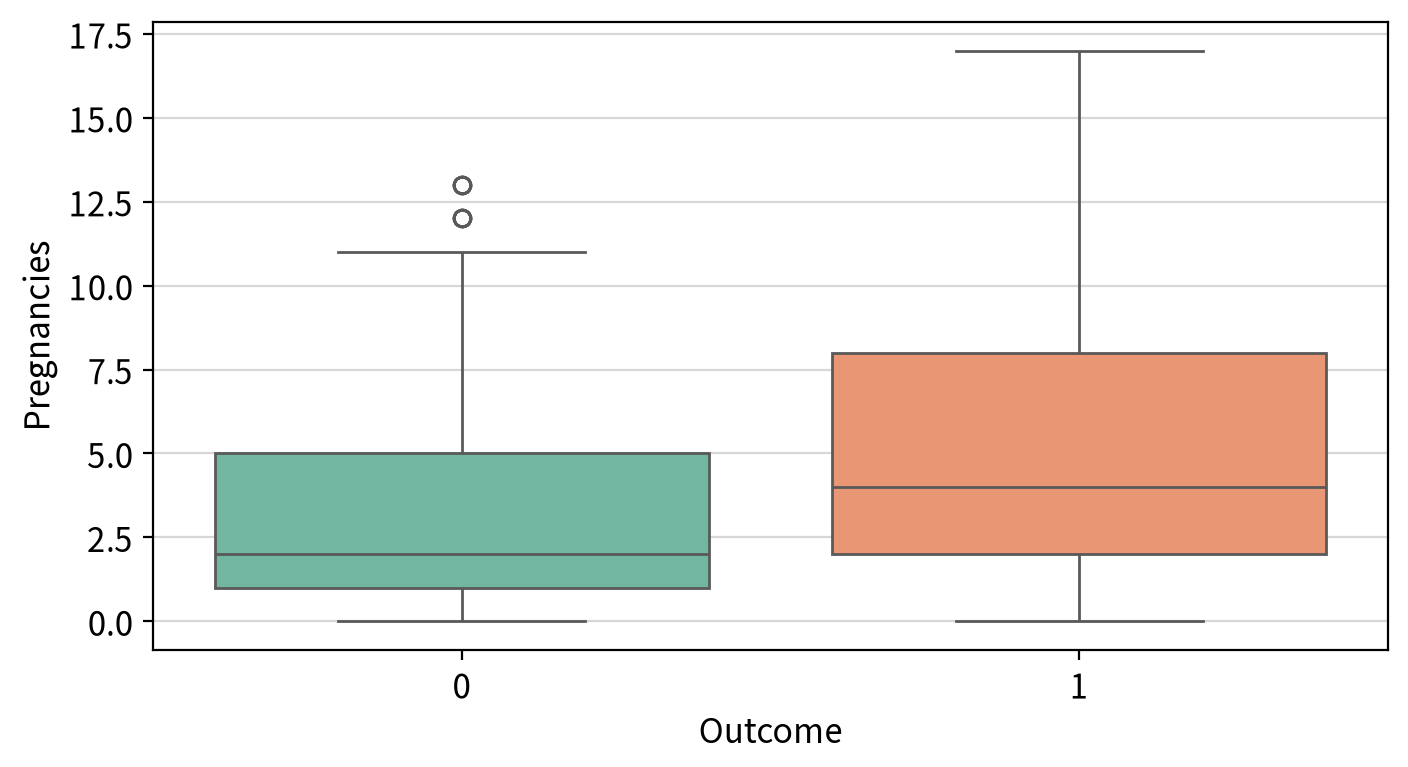

#### ▶︎ Glucose(포도당 부하 검사 수치) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    25047.000    0.000         True  0 ≠ 1
                    less         25047.000    0.000         True  0 < 1
                    greater      25047.000    1.000        False  0 ≤ 1

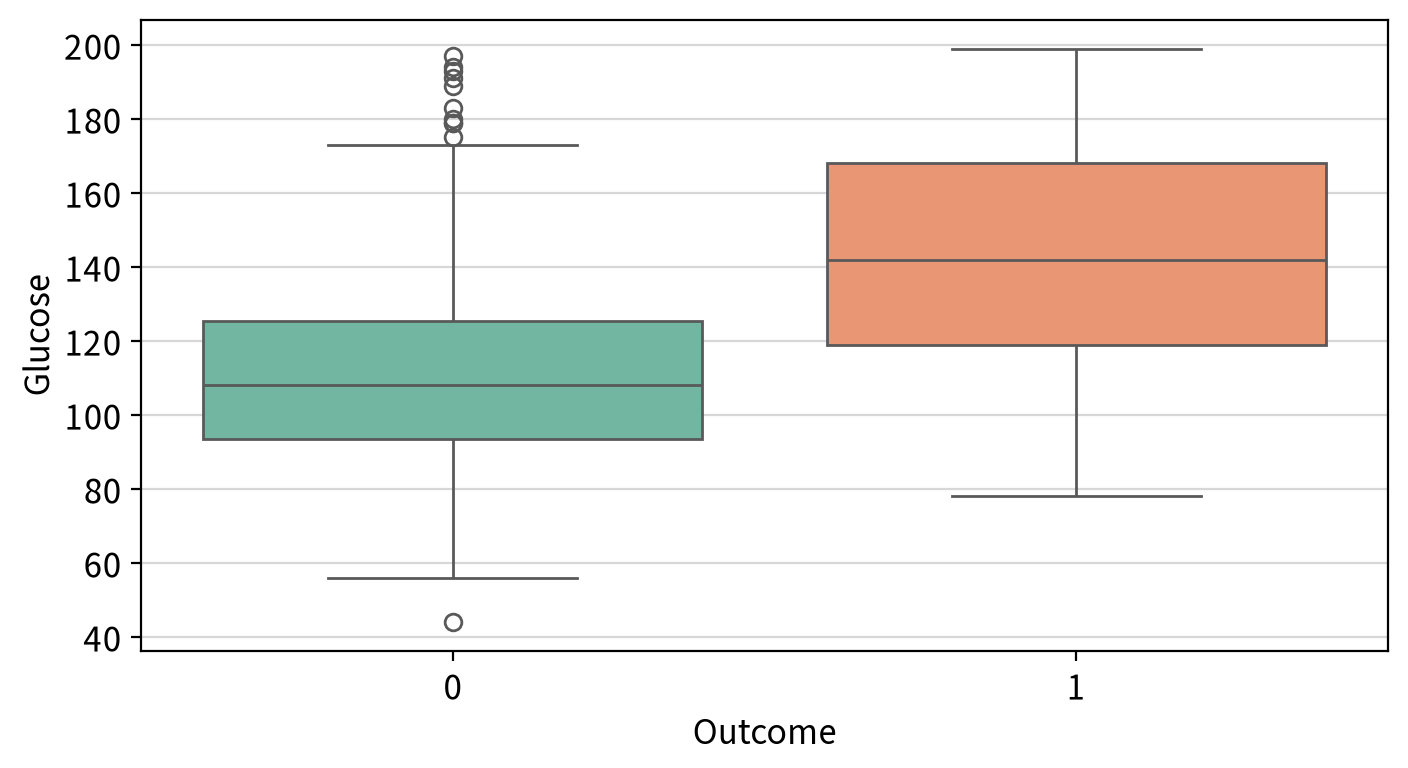

#### ▶︎ BloodPressure(혈압) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    46644.000    0.000         True  0 ≠ 1
                    less         46644.000    0.000         True  0 < 1
                    greater      46644.000    1.000        False  0 ≤ 1

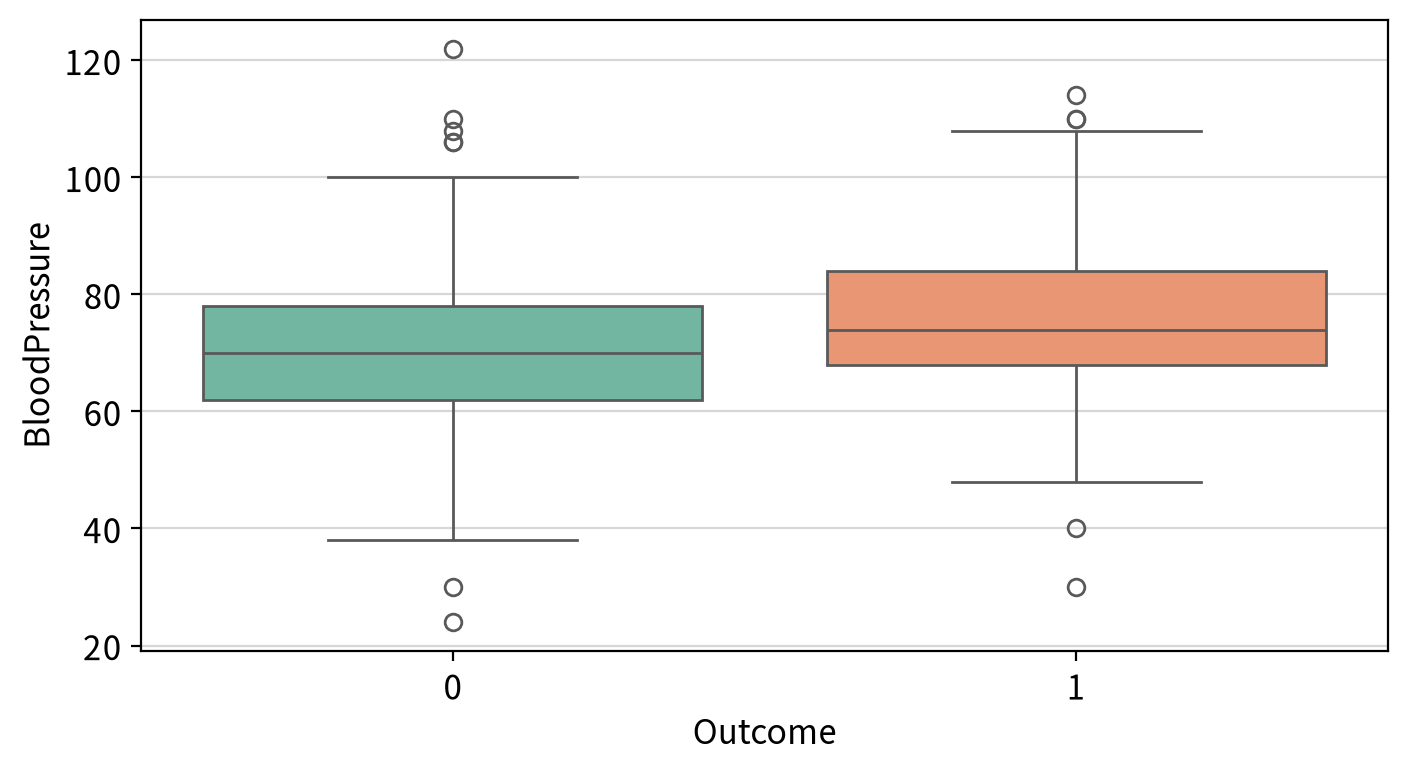

#### ▶︎ BMI( 체질량 지수) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    37919.500    0.000         True  0 ≠ 1
                    less         37919.500    0.000         True  0 < 1
                    greater      37919.500    1.000        False  0 ≤ 1

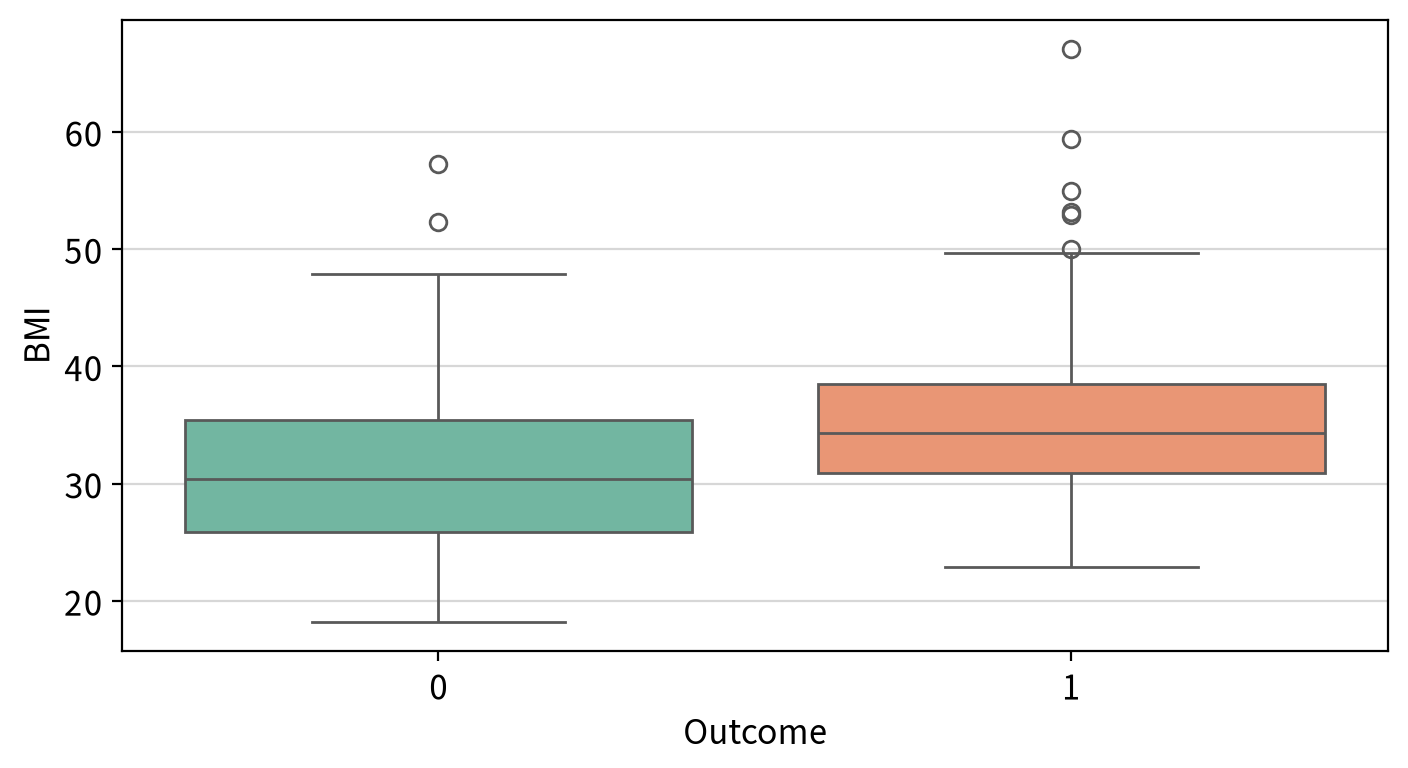

#### ▶︎ DiabetesPedigreeFunction(당뇨 내력 가중치 값) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    46035.000    0.000         True  0 ≠ 1
                    less         46035.000    0.000         True  0 < 1
                    greater      46035.000    1.000        False  0 ≤ 1

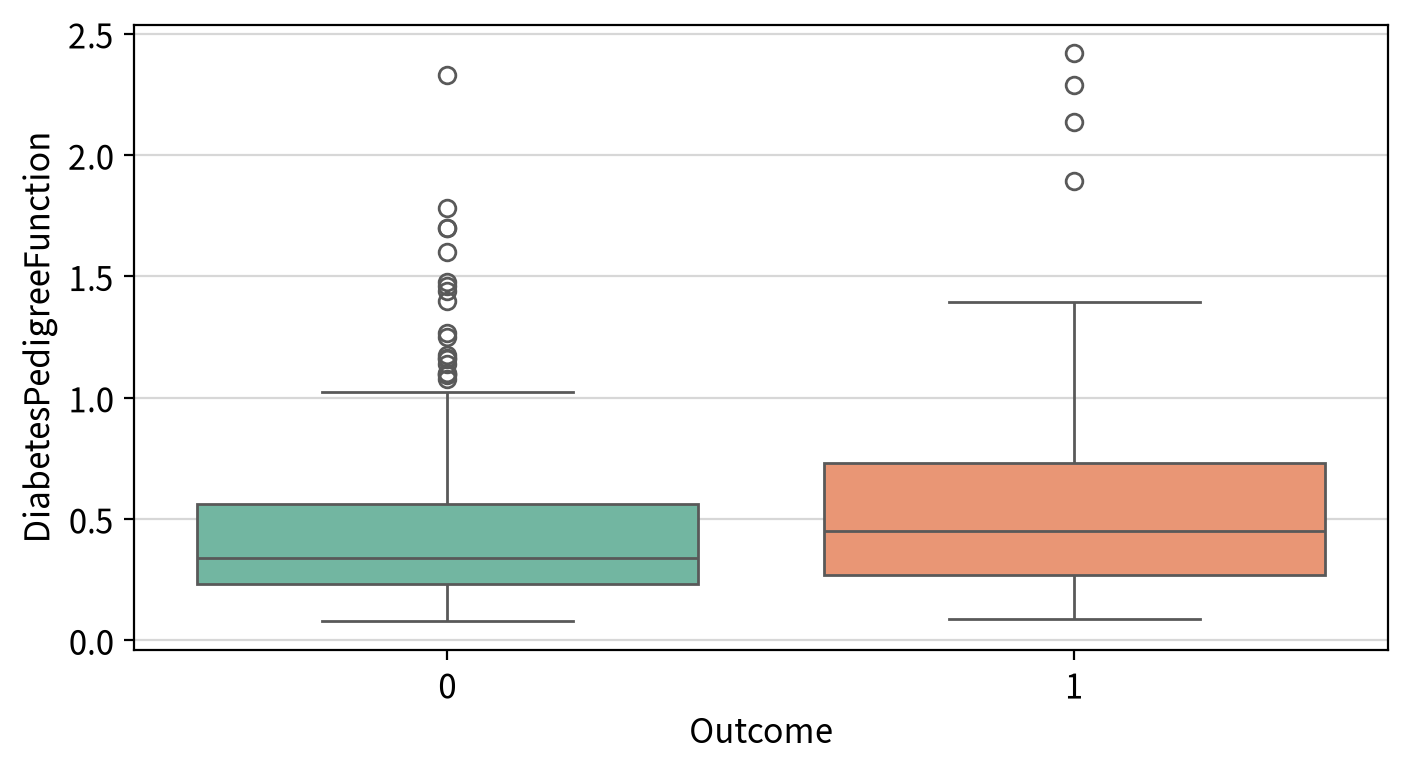

#### ▶︎ Age( 나이) → Outcome

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    37064.500    0.000         True  0 ≠ 1
                    less         37064.500    0.000         True  0 < 1
                    greater      37064.500    1.000        False  0 ≤ 1

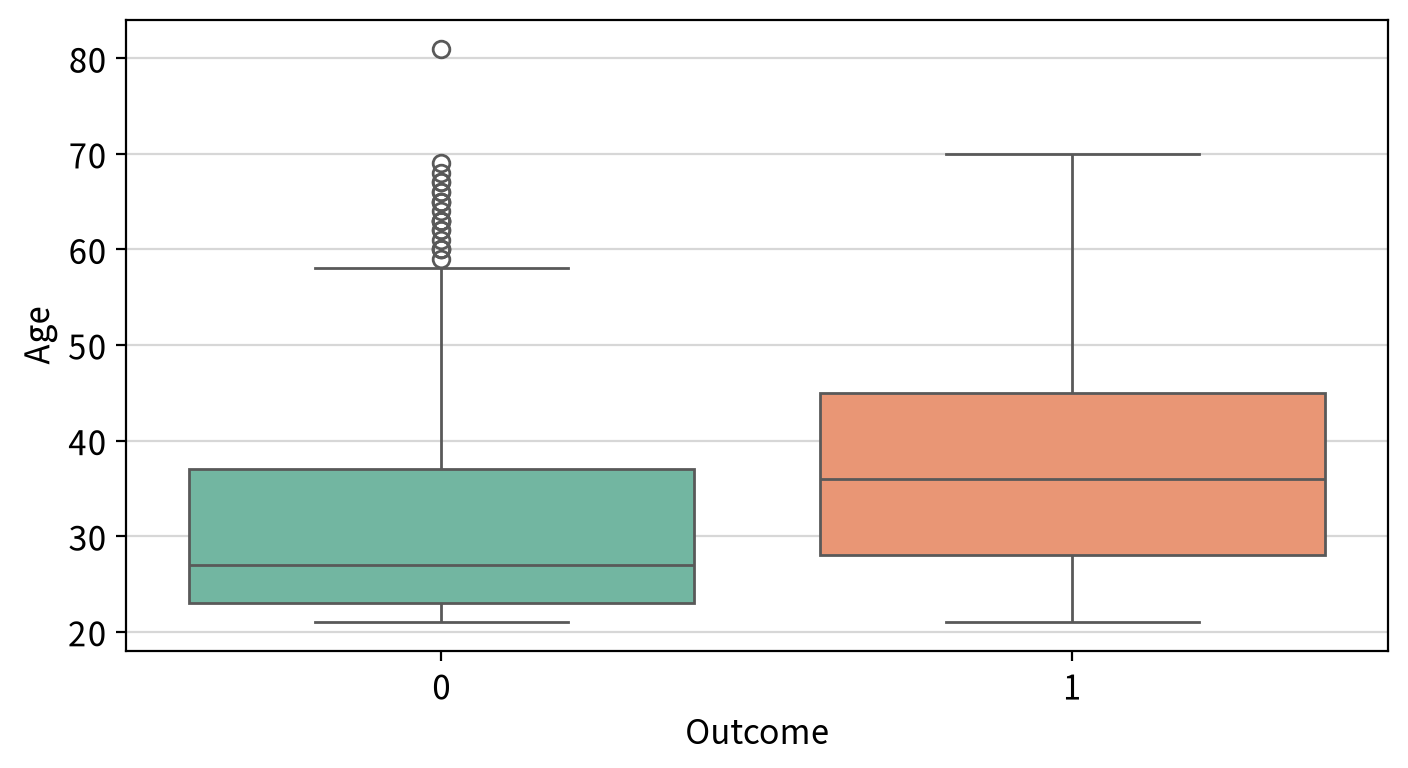

In [170]:
# 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    # -> 선형회귀 때와 hue/values 가 서로 뒤바뀐다. (종속변수가 집단 기준이 되므로)
    wide_df = my_prep.long2wide(df, hue=target, values=f)
    display(my_stats.test_independent(wide_df,
                group1=wide_df.columns[0], group2=wide_df.columns[1], plot=False))

    # 시각화: 종속변수 집단별 분포 비교
    my_plot.boxplot(data=df, x=target, y=f, hue=target, palette="Set2",
                    width=720, height=400)

#### 💡 인사이트

| 변수 | 검정 방법 | 유의확률 | 집단 차이 | 방향 | 단독 채택 |
|---|---|---|---|---|---|
| `Pregnancies` | Mann-Whitney U | < 0.001 | 유의 | `0` < `1` | ✅ |
| `Glucose` | Mann-Whitney U | < 0.001 | 유의 | `0` < `1` | ✅ |
| `BloodPressure` | Mann-Whitney U | < 0.001 | 유의 | `0` < `1` | ✅ |
| `BMI` | Mann-Whitney U | < 0.001 | 유의 |  `0` < `1`  | ✅ |
| `DiabetesPedigreeFunction` | Mann-Whitney U | < 0.001 | 유의 |  `0` < `1`  | ✅ |
| `Age` | Mann-Whitney U | < 0.001 | 유의 |  `0` < `1`  | ✅ |

</br>

> T 검정 결과, 6개 변수가 모두 유의하다고 판정되므로 모두 채택한다.

##### 교차분석 (x: 명목형 독립변수 → y: 명목형 종속변수)

- 명목형 독립변수가 있을 경우 카이제곱 독립성 검정을 수행한다.
  - 명목형 독립변수가 없을 경우 출력 결과가 없을 수 있다.

In [171]:
for n in nominal_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 교차분석 (카이제곱 독립성 검정)
    display(my_stats.chi2_independence(df, x=n, y=target, plot=False))

#### 💡 인사이트

> 이 데이터셋에는 **명목형 독립변수가 없으므로** 해당 없음. (출력 결과 없음)

#### 4-4. 다변량 분석 — 독립변수 간 상관

##### 독립변수간 상관 분석

- 연속형 독립변수끼리는 종속변수가 명목형이어도 상관분석을 그대로 쓸 수 있다.
- 목적이 다르다. 여기서는 **설명력 확인이 아니라 다중공선성 점검**이다.

In [172]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
Pregnancies,1.000,0.138,0.190,-0.002,-0.037,0.617
Glucose,0.138,1.000,0.249,0.214,0.086,0.274
BloodPressure,0.190,0.249,1.000,0.298,0.009,0.367
BMI,-0.002,0.214,0.298,1.000,0.129,0.110
DiabetesPedigreeFunction,-0.037,0.086,0.009,0.129,1.000,0.028
Age,0.617,0.274,0.367,0.110,0.028,1.000


,max-y,max-coef,count,columns
x,,,,
Age,Pregnancies,0.617,0,-
Pregnancies,Age,0.617,0,-
BloodPressure,Age,0.367,0,-
BMI,BloodPressure,0.298,0,-
Glucose,Age,0.274,0,-
DiabetesPedigreeFunction,BMI,0.129,0,-


##### 각 독립변수별 VIF
- 통상적인 경고 임계값 VIF >= 10

In [173]:
my_stats.compute_vif(df, columns=continuous_cols)

,VIF
Age,1.626
Pregnancies,1.455
BloodPressure,1.243
BMI,1.162
Glucose,1.156
DiabetesPedigreeFunction,1.043


#### 💡 인사이트

- `correlation_summary()`에서 **Strong(|r| ≥ 0.7) 조합이 하나도 나오지 않았다.**
- → **다중공선성 문제 없음.** 6개 변수를 모두 투입해도 계수가 불안정해지지 않는다.

#### 4-5. 최종 변수 선택

| 채택여부 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Pregnancies` | Mann-Whitney U | < 0.001 | `0` < `1` | X (VIF 1.46) | 집단 차이 유의 |
| ✅ 채택 | `Glucose` | Mann-Whitney U | < 0.001 | `0` < `1` | X (VIF 1.16) | 집단 차이 유의 |
| ✅ 채택 | `BloodPressure` | Mann-Whitney U | < 0.001 | `0` < `1` | X (VIF 1.24) | 집단 차이 유의 |
| ✅ 채택 | `BMI` | Mann-Whitney U | < 0.001 |  `0` < `1`  | X (VIF 1.16) | 집단 차이 유의 |
| ✅ 채택 | `DiabetesPedigreeFunction` | Mann-Whitney U | < 0.001 |  `0` < `1` | X (VIF 1.04) | 집단 차이 유의 |
| ✅ 채택 | `Age` | Mann-Whitney U | < 0.001 |  `0` < `1`  | X (VIF 1.63) | 집단 차이 유의 |

- 모든 변수가 유의하고 다중공선성이 없으므로 전부 모델에 투입한다.

## #5. 모델링

#### 5-1. 종속변수 라벨링

- 로지스틱 회귀의 종속변수는 **0/1의 정수**여야 한다.
- `my_prep.labeling()`은 **알파벳 순서**로 0부터 매긴다.
- 이 모형이 예측하는 것은 **P(Outcome = 1)** 이고,
  뒤에 나오는 오즈비는 모두 **"환자가 `1`(당뇨)일 오즈"** 에 대한 값이다.

In [174]:
base = my_prep.labeling(df, columns=[target])
base.head()

Outcome (2 종): 0=0, 1=1


,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.000,72.000,33.600,0.627,50,1
1,1,85.000,66.000,26.600,0.351,31,0
2,8,183.000,64.000,23.300,0.672,32,1
3,1,89.000,66.000,28.100,0.167,21,0
4,0,137.000,40.000,43.100,2.288,33,1


#### 5-2. 기준선 모형 적합

In [175]:
fit_base = my_logit.fit_model(base, y=target)
my_logit.report_variables(fit_base, base)

,종속변수,독립변수,B,βstd,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Outcome,DiabetesPedigreeFunction,0.961,0.319,0.306,3.135,0.002,0.360,1.561,2.613,1.433,4.764,0.959,1.043
1,Outcome,Pregnancies,0.118,0.396,0.033,3.527,0.000,0.052,0.183,1.125,1.054,1.201,0.687,1.455
2,Outcome,BMI,0.091,0.626,0.016,5.777,0.000,0.060,0.122,1.095,1.062,1.130,0.860,1.162
3,Outcome,Glucose,0.035,1.082,0.004,9.763,0.000,0.028,0.042,1.036,1.029,1.043,0.865,1.156
4,Outcome,Age,0.017,0.199,0.010,1.723,0.085,-0.002,0.036,1.017,0.998,1.037,0.615,1.626
5,Outcome,BloodPressure,-0.009,-0.110,0.009,-1.035,0.301,-0.026,0.008,0.991,0.975,1.008,0.804,1.243


#### 💡 인사이트
 - 유의수준 0.05 초과 변수는 BloodPressure (0.301)와 Age (0.085) — 2개
 - 유의하지 않다고 무의미한 변수는 아님. 다른 변수를 통제한 상태에서 추가로 설명하는 부분이 없다는 뜻
 - 이 상태에서 변수를 지우지 않고, **가정 검정부터 수행한다.**

## #6. 모형 진단과 개선

#### 6-1. 가정 검토

##### 기준선 모형의 로짓 선형성 검정 (Box-Tidwell)

- 독립변수 x에 `x × ln(x)` 항을 추가해 **그 항이 유의한지** 본다.
  - 유의하면(p < 0.05) 로짓이 직선이 아니라는 뜻 → 변환·제곱항·구간화가 필요하다.

In [176]:
my_logit.test_linear(fit_base, base)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Pregnancies,0.020,0.984,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Glucose,-1.084,0.278,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
BloodPressure,-0.564,0.573,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
BMI,-2.224,0.026,False,False,대립가설 채택 → 로짓 선형성 위배(변환 필요)
DiabetesPedigreeFunction,-2.239,0.025,False,False,대립가설 채택 → 로짓 선형성 위배(변환 필요)
Age,-4.460,0.000,False,False,대립가설 채택 → 로짓 선형성 위배(변환 필요)


> **결과** — `Age`(p = 0.000, z = −4.46) · `DiabetesPedigreeFunction`(p = 0.025) · `BMI`(p = 0.026) **위배**.  
> 나머지 세 변수는 충족. **위배가 가장 심한 `Age`부터 처방한다.**

#### 6-2. 가정 위반에 대한 조치

##### 진단 → 처방 → 검증 → 재진단 루프

In [177]:
fit_fixed = my_logit.fix_linear(base, y=target)

[라운드 1] 위배 3종 → 'Age' 처방 (z = -4.4596)
  → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 2.5579e-06, AIC = 666.74)
[라운드 2] 위배 1종 → 'DiabetesPedigreeFunction' 처방 (z = -2.737)
  → 제곱항 채택 (제곱항 p = 0.0031, 우도비 p = 7.2500e-03, AIC = 661.53)
[라운드 3] 위배 변수 없음 → 루프 종료



,변수,처방,제곱항 p,검증 p,AIC,채택
라운드,,,,,,
1,Age,제곱항,0.000,0.000,666.740,True
2,DiabetesPedigreeFunction,제곱항,0.003,0.007,661.530,True


> `Age`, `DiabetesPedigreeFunction` 처방 후, `BMI`는 저절로 해소되어 처방하지 않았다.

In [178]:
from statsmodels.api import add_constant, Logit

# 아직 변환하지 않은 연속형 독립변수만 재검정
check_cols = ["Pregnancies", "Glucose", "BloodPressure", "BMI"]

# 제곱항 모형의 독립변수 전체 (보조항을 넣을 때 함께 통제해야 한다)
xnames1 = list(fit_fixed.data_.columns.drop("Outcome"))

rows = []                               # 결과를 담을 리스트

for col in check_cols:
    bt = fit_fixed.data_[xnames1].copy()            # 독립변수만 복사
    base1 = bt[col]                      # 독립변수의 값
    if base1.min() <= 0:                 # 최소값이 0 이하라면?  
        base1 = base1 - base1.min() + 1    # ln의 정의역(양수)을 맞추기 위한 평행이동

    bt["보조항"] = base1 * np.log(base1)   # x * ln(x) 보조항 추가

    # 보조항을 포함해 다시 적합
    bt_fit = Logit(fit_fixed.data_["Outcome"], add_constant(bt)).fit(disp=0)

    # 결과표 구성
    rows.append({
        "독립변수": col,
        "z": bt_fit.tvalues["보조항"],
        "유의확률": bt_fit.pvalues["보조항"],
        "로짓선형성": bt_fit.pvalues["보조항"] >= 0.05,
    })

DataFrame(rows).set_index("독립변수").round(4)

,z,유의확률,로짓선형성
독립변수,,,
Pregnancies,0.510,0.610,True
Glucose,-1.035,0.301,True
BloodPressure,-0.383,0.702,True
BMI,-1.640,0.101,True


> **결과** — `BMI`는 0.026 → **0.101로 저절로 해소**됐다. (나이를 직선으로 잘못 넣은 탓에 곡선 효과가 BMI로 번져 있었다)

##### 계층 원칙

- 제곱항을 넣으면 1차항이 유의하지 않게 나오는 경우가 있다. 후진소거법이라면 제거 대상이다.
- 하지만 **제곱항이 모형에 있으면 1차항은 유의하지 않아도 남긴다.** 이것을 **계층 원칙(hierarchy principle)** 이라 한다.
  - 1차항을 빼면 곡선의 **꼭짓점이 중심값에 고정**되어 버려, 데이터가 말하는 곡선 모양을 왜곡한다.
- 실제로 지워도 되는지는 **6-4의 성능 비교표**에서 후진소거 적용 모형과 나란히 놓고 판단한다.

#### 6-3. 관측치 독립성과 가정 검정 결과 확정

##### 관측치의 독립성 — Durbin-Watson

In [179]:
my_logit.test_independent(fit_fixed)

,statistic,independence,result
Durbin-Watson,1.906,True,독립성 만족


> **결과** — DW = **1.906**로 기준 범위(1.5 ~ 2.5) 안에 있다. → **독립성 만족.**
>
> ※ DW는 본래 시계열 전용 검정이다. 수집 순서에 의미가 없는 자료라면 위배로 나와도 무시할 수 있고,
> 반대로 같은 사람을 반복 측정한 자료라면 DW가 정상이어도 독립성이 깨진 것이다. **독립성은 자료 수집 설계로 판단한다.**

##### 가정 검정 결과 확정

- 처방 대상 변수 목록을 확정한다. 이 목록이 **다음 단계 파이프라인의 옵션**이 된다.

In [180]:
# 확정된 처방 내역 (변수별 처방 방식과 기준값)
recipe = fit_fixed.recipe_

for col, rule in recipe.items():
    print(f"{col:14s} : {rule['method']}")

extra_cols = [c for c in continuous_cols if c not in recipe]
print("\n처방 제외 (선형성 충족) :", extra_cols)
print("미해소 (구간화·스플라인 필요) :", fit_fixed.unresolved_)

Age            : square
DiabetesPedigreeFunction : square

처방 제외 (선형성 충족) : ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI']
미해소 (구간화·스플라인 필요) : []


#### 6-4. 로지스틱 회귀 파이프라인

##### 전처리 체크포인트 정의

- 전처리 단계를 하나씩 누적한 체크포인트 (아래로 갈수록 전처리가 하나 더 붙는다)
- **0~2번은 가정 검정을 반영하지 않은 조합**, **3~5번은 `recipe`를 적용한 조합**이다.
  - 두 계열의 전처리 조합을 **동일하게 맞춰** 로짓 선형성 처방의 순수한 효과를 볼 수 있게 한다.
- 공선성 제거(`vif=True`)는 **모든 체크포인트에 공통으로** 걸어 둔다.
  - 4-4에서 이미 제거 대상이 없음을 확인했으므로, 별도의 비교 단계로 쪼갤 이유가 없다.

In [181]:
checkpoints = {
    # --- 가정 검정 미반영 ---
    "0_기준선":             dict(vif=True),
    "1_후진소거":           dict(backward=True, vif=True),
    "2_정규화":             dict(backward=True, vif=True, scale=True),

    # --- 가정 검정 반영 (로짓 선형성 처방) ---
    "3_가정반영":           dict(recipe=recipe, vif=True),
    "4_가정반영+후진소거":   dict(recipe=recipe, backward=True, vif=True),
    "5_가정반영+정규화":     dict(recipe=recipe, backward=True, vif=True, scale=True),
}

> 의료 데이터에 대한 이상치는 실제 측정된 수치라 판단하여 처리하지 않기로 결정했기 때문에, 체크포인트에도 이상치 대체 처리는 들어가지 않았다.

##### 체크포인트별 모델 적합

In [182]:
fits = {}    # 적합된 모델을 누적할 딕셔너리

for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")

    fits[name] = my_logit.fit_pipeline(
        base, target, continuous_cols, name=name, **checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.63


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.63

유의하지 않은 독립변수 제거 → BloodPressure (p = 0.3008)
유의하지 않은 독립변수 제거 → Age (p = 0.1284)

▶︎ --- 2_정규화 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.63

유의하지 않은 독립변수 제거 → BloodPressure (p = 0.3008)
유의하지 않은 독립변수 제거 → Age (p = 0.1284)

▶︎ --- 3_가정반영 ---

완료! 남은 변수: ['Age_c', 'Age_c2', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction_c', 'DiabetesPedigreeFunction_c2', 'Glucose', 'Pregnancies']
최대 VIF = 3.57


▶︎ --- 4_가정반영+후진소거 ---

완료! 남은 변수: ['Age_c', 'Age_c2', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction_c', 'DiabetesPedigreeFunction_c2', 'Glucose', 'Pregnancies']
최대 VIF = 3.57

유의하지 않은 독립변수 제거 → Pregnancies (p = 0.2347)
유의하지 않은 독립변수 제거 → BloodPressure (p = 0.1250)

##### 전체 모델 성능 비교

In [183]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
1_후진소거,4,0.778,0.725,0.570,0.638,0.841,0.274,686.227,1.760
2_정규화,4,0.778,0.725,0.570,0.638,0.841,0.274,686.227,1.760
4_가정반영+후진소거,6,0.782,0.722,0.594,0.652,0.854,0.305,661.312,0.210
5_가정반영+정규화,6,0.782,0.722,0.594,0.652,0.854,0.305,661.312,0.210
0_기준선,6,0.776,0.721,0.570,0.637,0.843,0.278,686.861,1.500
3_가정반영,8,0.779,0.717,0.590,0.648,0.856,0.309,661.529,0.000


간명성 기준 1순위 : 1_후진소거


##### 최종 모델 선택

- `my_logit.compare_models()`는 근소 격차 그룹 안에서 **변수가 적은 `1_후진소거`(변수 4개)를 1순위**로 지목한다.
- 하지만 **`4_가정반영+후진소거`(변수 6개)를 채택**한다.
  - 변수는 2개 늘었지만, 정밀도(0.725 → 0.722)를 제외한 모든 지표가 좋아진다.
    정확도 0.778 → 0.782, 재현율 0.570 → 0.594, F1 0.638 → 0.652, AUC 0.841 → 0.854, Pseudo R² 0.274 → 0.305, AIC 686.227 → 661.312.
  - 가정 반영 계열의 `3_가정반영`(변수 8개)과는 AUC(0.856 vs 0.854)·Pseudo R²(0.309 vs 0.305)가 근소하게 `3_가정반영` 쪽이 높고 AIC(661.529 vs 661.312)는 `4_가정반영+후진소거` 쪽이 낮아 **성능이 거의 같다.** 같은 성능이라면 변수가 2개 적은 쪽이 간명하다.
  - 후진소거로 제거된 `Pregnancies`(p = 0.2347)와 `BloodPressure`(p = 0.1250)는 제곱항의 1차항이 아닌 독립변수라서 **계층 원칙에 어긋나지 않는다.**
  - → 자동 선택 결과는 언제나 분석자가 검토해야 한다.


In [184]:
# 가정 반영 + 후진소거 모델을 선택한다. (자동 1순위는 1_후진소거)
final_name = "4_가정반영+후진소거"

final_fit = fits[final_name]
final_data = final_fit.data_       # 전처리가 끝난 데이터 (보고에 사용)

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 4_가정반영+후진소거
독립변수  : 6 개


## #7. 결과 해석

#### 7-1. 모형 적합도와 회귀계수 해석

##### 모형 적합도

In [185]:
Markdown(my_logit.report_fitness(final_fit))

**Note. n = 724. LL = -323.656, LL-Null = -465.969, LLR χ²(6) = 284.626, p < 0.001, Pseudo R² = 0.305**

Outcome를 종속변수로, Glucose, BMI, Age_c, Age_c2, DiabetesPedigreeFunction_c, DiabetesPedigreeFunction_c2(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(6) = 284.626, p < 0.001, Pseudo R² = 0.305.

즉, 모형의 유사결정계수는 0.305로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

##### 독립변수 보고

In [186]:
display(my_logit.report_variables(final_fit, final_data))
Markdown(my_logit.report_variables_text(final_fit, data=final_data))

,종속변수,독립변수,B,βstd,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Outcome,DiabetesPedigreeFunction_c,1.627,0.541,0.411,3.961,0.000,0.822,2.433,5.091,2.276,11.389,0.510,1.961
1,Outcome,DiabetesPedigreeFunction_c2,-1.239,-0.377,0.424,-2.921,0.004,-2.071,-0.408,0.290,0.126,0.665,0.512,1.955
2,Outcome,Age_c,0.084,0.988,0.013,6.674,0.000,0.059,0.109,1.088,1.061,1.115,0.494,2.022
3,Outcome,BMI,0.077,0.532,0.015,5.087,0.000,0.047,0.107,1.080,1.049,1.113,0.909,1.101
4,Outcome,Glucose,0.036,1.111,0.004,9.798,0.000,0.029,0.043,1.037,1.029,1.044,0.870,1.150
5,Outcome,Age_c2,-0.004,-0.799,0.001,-5.392,0.000,-0.005,-0.002,0.996,0.995,0.998,0.509,1.963


- **Glucose**의 회귀계수는 **B = 0.0361**, 오즈비는 **OR = 1.0368**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = 9.8**, **p < .001**) 즉, **Glucose**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **3.7% 증가**하는 것으로 해석된다.
- **BMI**의 회귀계수는 **B = 0.0772**, 오즈비는 **OR = 1.0803**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = 5.09**, **p < .001**) 즉, **BMI**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **8.0% 증가**하는 것으로 해석된다.
- **Age_c**의 회귀계수는 **B = 0.084**, 오즈비는 **OR = 1.0876**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = 6.67**, **p < .001**) 즉, **Age_c**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **8.8% 증가**하는 것으로 해석된다.
- **Age_c2**의 회귀계수는 **B = -0.0037**, 오즈비는 **OR = 0.9963**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = -5.39**, **p < .001**) 즉, **Age_c2**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **0.4% 감소**하는 것으로 해석된다.
- **DiabetesPedigreeFunction_c**의 회귀계수는 **B = 1.6275**, 오즈비는 **OR = 5.0909**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = 3.96**, **p < .001**) 즉, **DiabetesPedigreeFunction_c**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **409.1% 증가**하는 것으로 해석된다.
- **DiabetesPedigreeFunction_c2**의 회귀계수는 **B = -1.2393**, 오즈비는 **OR = 0.2896**로 나타났으며, 이는 **Outcome**에 유의한 요인임을 의미한다. (**z = -2.92**, **p = .003**) 즉, **DiabetesPedigreeFunction_c2**가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **71.0% 감소**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.**
> 변수 간 값의 범위가 동일한 경우만 오즈비를 직접 비교할 수 있다.
> 값의 범위가 서로 다르면 범위를 통일한 **표준화 계수(βstd)** 로 영향력을 비교해야 한다.

##### 오즈비 시각화

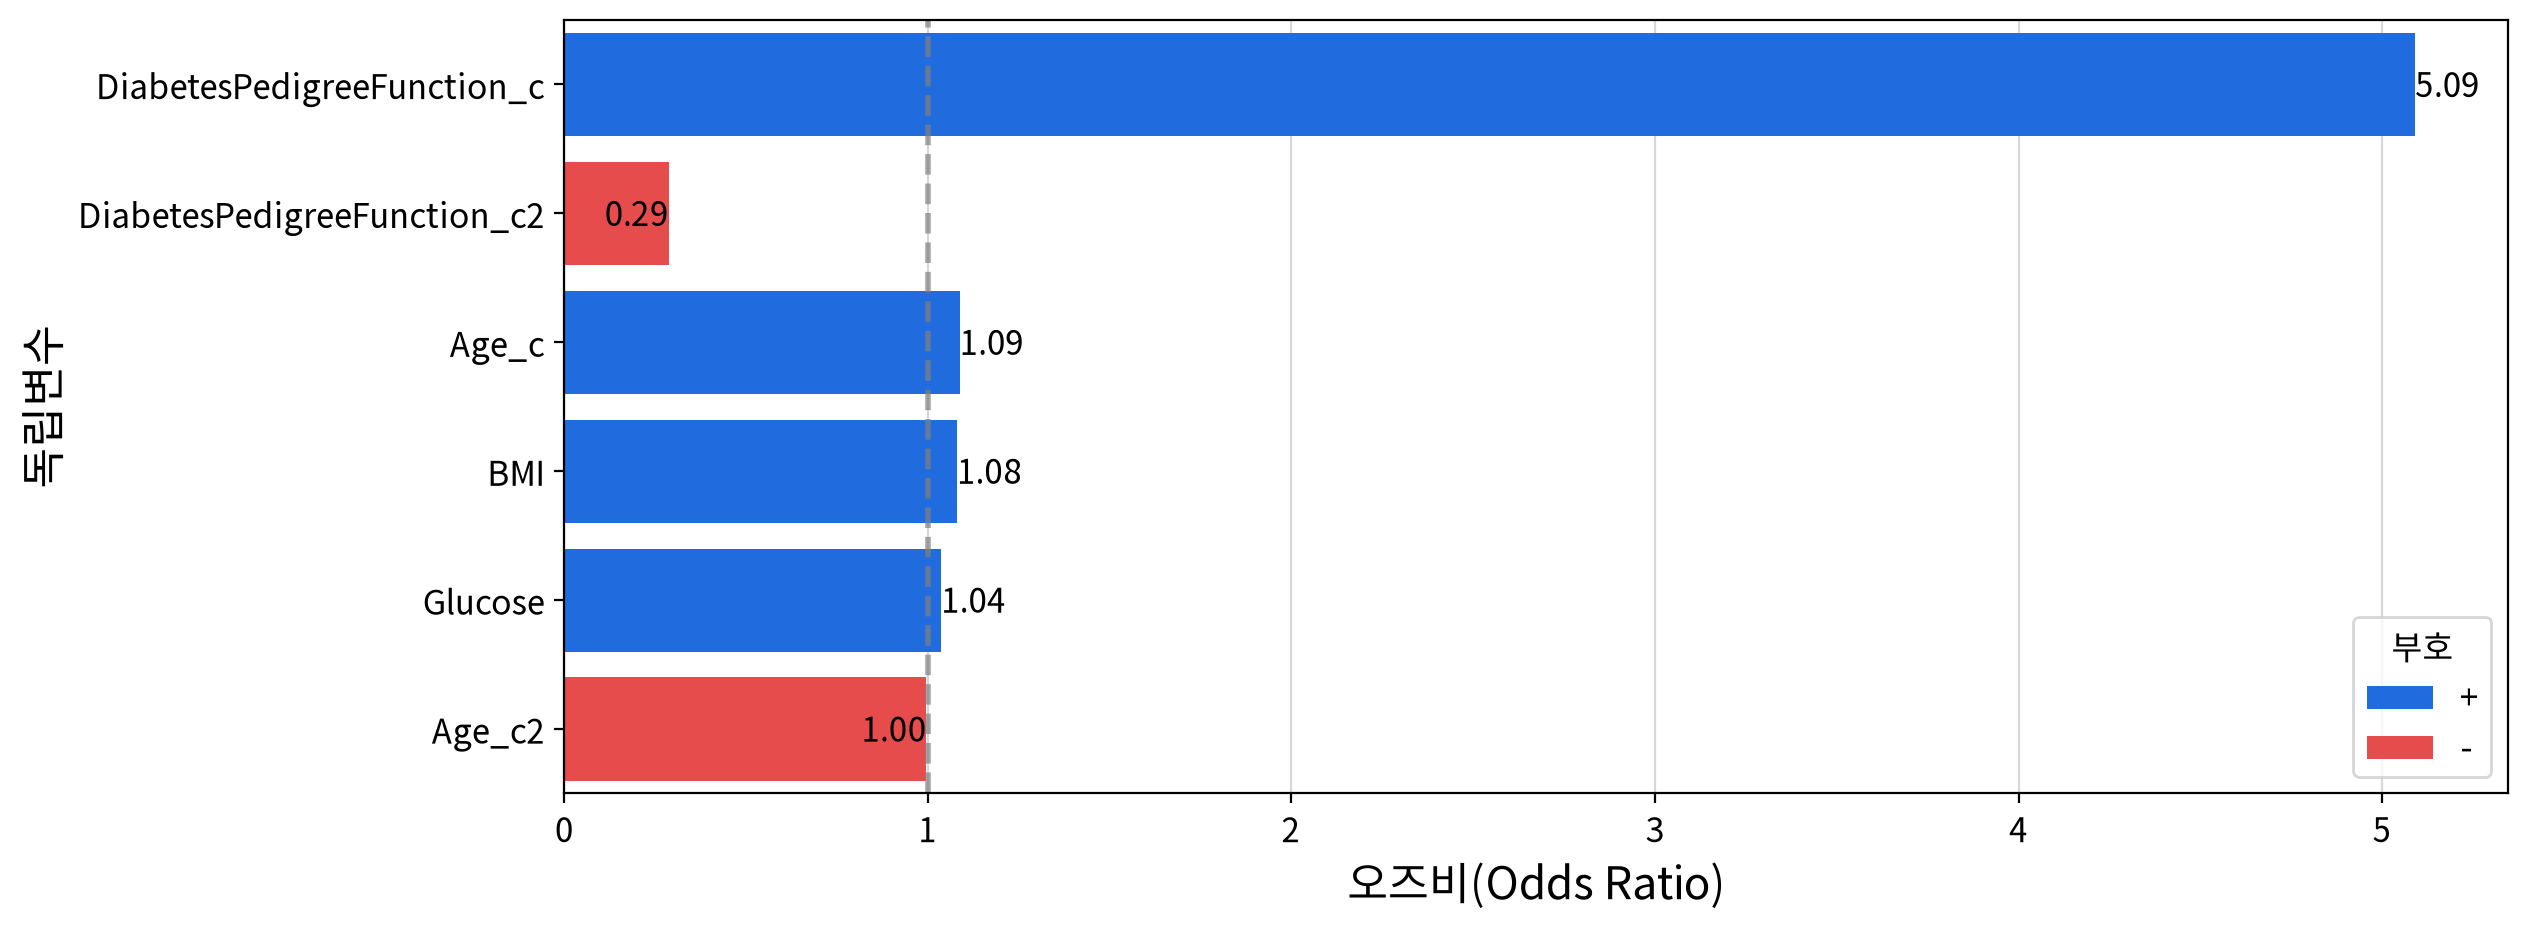

In [187]:
my_logit.plot_odds(final_fit, final_data)

#### 💡 인사이트 — 계수 해석

**모형 요약** — `logit(P(Outcome = 1)) ~ Glucose + BMI + (Age_c + Age_c2) + (DiabetesPedigreeFunction_c + DiabetesPedigreeFunction_c2)` (최종 모형 `4_가정반영+후진소거`, n = 724)

- **LLR χ²(6) = 284.63, p < .001, Pseudo R² = 0.305** 로 우수한 적합이다(0.2~0.4 구간). 6개 항이 모두 p < .01로 유의하다.
- 후진소거로 `Pregnancies`(p = 0.2347)와 `BloodPressure`(p = 0.1250)가 제거되어 독립변수가 8개 → 6개로 줄었다.
- **영향력 1위는 `Glucose`** 다. 표준화 계수 βstd = 1.111로, 2위 `Age`(`Age_c` 0.988 · `Age_c2` −0.799)와 근소하다. `DiabetesPedigreeFunction`(0.541 · −0.377)과 `BMI`(0.532)가 그 뒤를 잇는다.

**1차항만 있는 변수 (직선 관계)**

| 변수 | B | 오즈비 | 해석 |
|---|---|---|---|
| `Glucose` | 0.036 | 1.037 | 포도당 부하 검사 수치 1 ↑ → 당뇨일 오즈 **3.7% 증가** |
| `BMI` | 0.077 | 1.080 | 체질량 지수 1 ↑ → 당뇨일 오즈 **8.0% 증가** |

**1차항 + 제곱항이 있는 변수 (곡선 관계)**

⚠️ 제곱항이 있는 변수는 **오즈비를 한 줄로 해석하지 않는다.** 두 계수가 함께 곡선을 만든다. (`_c`는 중심화한 값이다.)

| 변수 | 1차항 B | 제곱항 B | 곡선 모양 | 해석 |
|---|---|---|---|---|
| `Age` | +0.084 | −0.0037 | 위로 볼록 ∩ | 나이가 많을수록 당뇨 오즈가 커지지만 **어느 지점부터 증가세가 꺾인다** |
| `DiabetesPedigreeFunction` | +1.627 | −1.239 | 위로 볼록 ∩ | 당뇨 내력 가중치가 높을수록 오즈가 커지지만 **어느 지점부터 효과가 꺾인다** |

- **`Age`가 이 분석의 가장 큰 반전이다.**
  단독 비교(Mann-Whitney U)에서는 유의(p < .001)했지만, 직선만 표현하는 기준선 모형에서는 p = 0.085로 **비유의**였고
  `1_후진소거` 모델에서는 p = 0.1284로 **제거**됐다. 그러나 제곱항을 넣자 `Age_c` z = 6.67, `Age_c2` z = −5.39로 **2위 영향력 변수**가 됐다.
  - **Box-Tidwell 검정(z = −4.46)에서만 잡히는** 관계였다. 직선 모형이었다면 이 변수를 버렸을 것이다.
- **`Pregnancies`는 반대로 유의성을 잃었다.** 기준선 모형에서는 p < .001이었지만 `Age`의 곡선을 반영하자 p = 0.2347로 비유의가 되어 제거됐다. (`Age`와의 상관계수 0.617)
- ⚠️ **오즈비가 가장 큰 항이 영향력이 가장 큰 항은 아니다.** `DiabetesPedigreeFunction_c`의 오즈비(5.091)가 가장 크지만 βstd는 0.541이고 `Glucose`(1.111)가 1위다.
  이 변수는 값의 범위가 0.078 ~ 2.420으로 좁아 "1 증가"의 크기가 다르기 때문이며, 영향력은 **βstd로 비교**한다.


#### 7-2. 분류 성능 평가와 임계값 조정

##### 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),418,57
실제 1 (Positive),101,148


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.782,0.722,0.594,0.120,0.880,0.652,0.854,우수,10.746


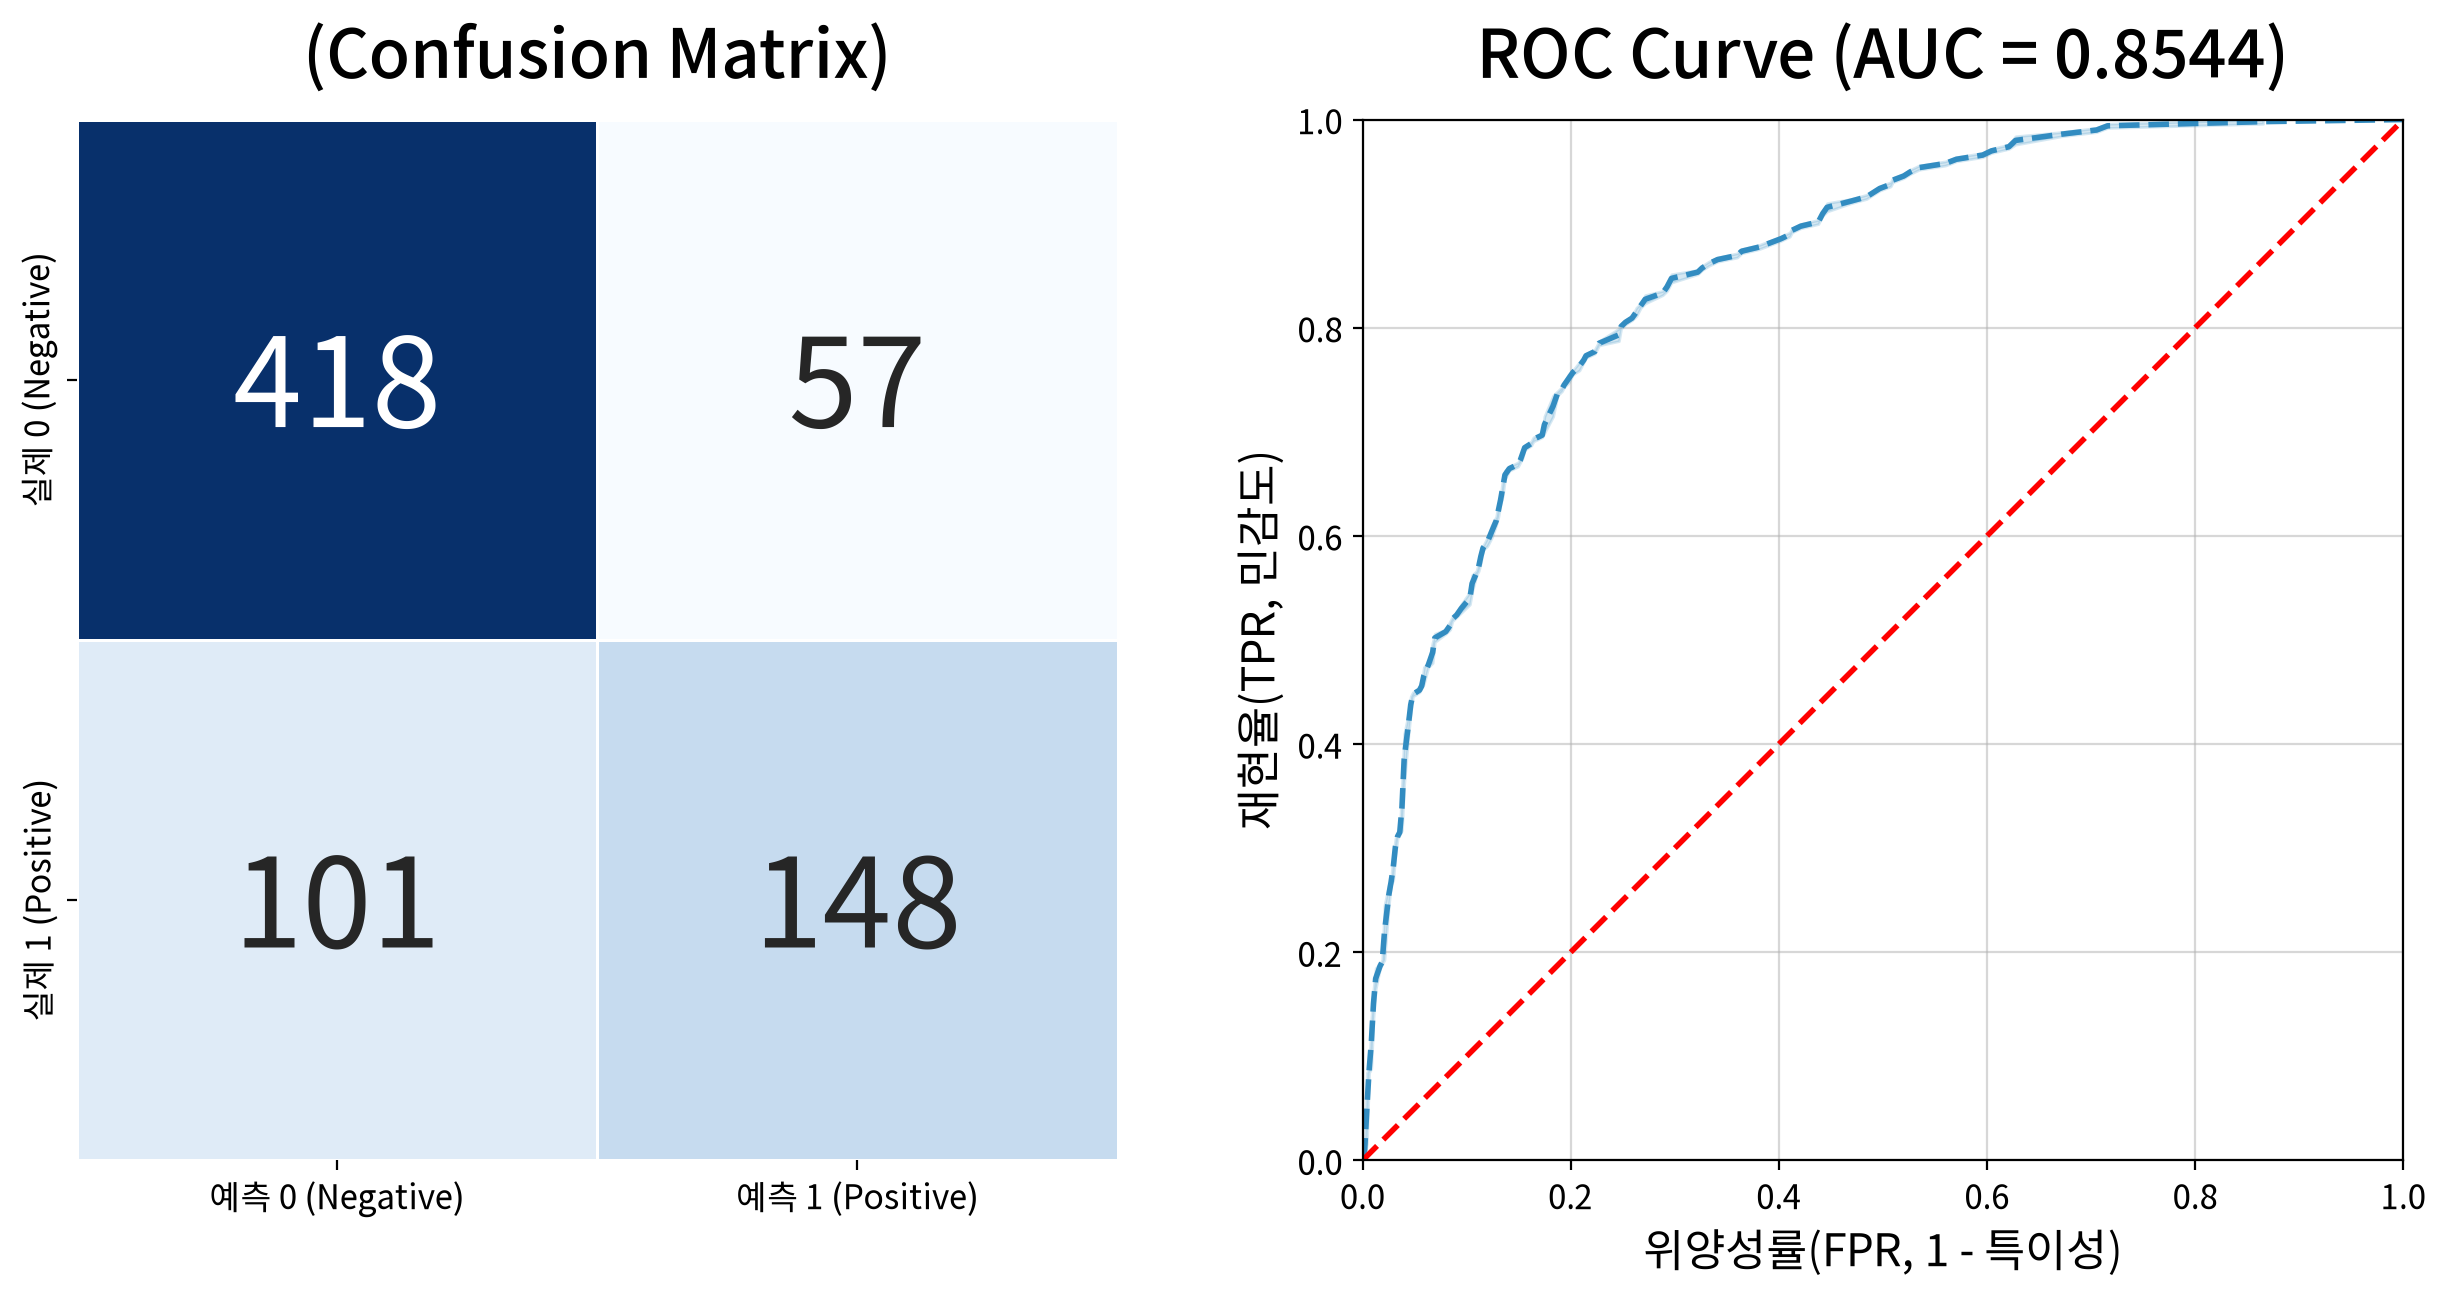

In [188]:
my_logit.report_performance(final_fit)

#### 💡 인사이트

- **정확도 0.782** — 게으른 모형의 바닥값 65.6%보다 **12.6%p 높다.**
- **AUC 0.854 (우수)** — `0` 인 환자와 `1` 인 환자를 무작위로 뽑았을 때,
  모형이 `1` 쪽에 더 높은 확률을 줄 가능성이 **85.4%** 다.
- **정밀도 0.722 · 재현율 0.594 · 특이성 0.880으로 재현율이 낮다**(당뇨 249명 중 101명을 놓침)
- **진단 오즈비 10.75** — 모형이 `1`이라고 판정한 환자가 실제로 `1`일 오즈는
  `0`라고 판정한 환자의 **약 10.7배**다.


##### 임계값 조정

- 임계값 0.5는 관례일 뿐 **정답이 아니다.** 목적에 따라 조정한다.

In [189]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,놓친 1(FN),잘못 잡은 0(FP)
임계값,,,,,,
0.300,0.762,0.616,0.819,0.703,45,127
0.400,0.783,0.674,0.715,0.694,71,86
0.500,0.782,0.722,0.594,0.652,101,57
0.600,0.782,0.783,0.506,0.615,123,35
0.700,0.769,0.831,0.414,0.552,146,21


#### 💡 인사이트

- **정확도는 0.4에서 최대(0.783)** 지만(0.5와 0.6은 0.782), **F1은 0.3에서 최대(0.703)** 다.
- **트레이드오프가 그대로 나타난다.** 임계값 0.3 → 재현율 0.819 / 정밀도 0.616,
  임계값 0.7 → 정밀도 0.831 / 재현율 0.414.
- **놓치는 환자 수도 크게 달라진다.** 임계값 0.5에서는 당뇨 249명 중 101명을 놓치지만, 0.3에서는 45명으로 줄어든다. 대신 잘못 잡는 정상(`0`)은 57명 → 127명으로 늘어난다.
- **정답은 목적이 정한다.**
    -  선별검사라면 **임계값을 낮춰** 재현율을 올린다.
    -  확진 단계처럼 오경보 비용이 크다면 **임계값을 높여** 정밀도를 확보한다.


#### 7-3. 질문별 답변과 가설 판정

> 최종 채택 모형 `4_가정반영+후진소거`(= `final_fit`, 독립변수 6개 항)의 결과를 바탕으로 #1의 분석 질문과 2-3의 가설에 답한다.
> (7-1 `report_fitness`·`report_variables`, 7-2 `report_performance` 출력 기준)

**Q1. 당뇨병 여부(`Outcome` = 1)에 가장 큰 영향을 주는 요인은 무엇인가?**

| 순위 | 변수 | 표준화계수(βstd) | 오즈비(OR) |
|---|---|---|---|
| 1 | `Glucose` | **1.111** | 1.037 |
| 2 | `Age` | `Age_c` 0.988 / `Age_c2` −0.799 | 1.088 / 0.996 |
| 3 | `DiabetesPedigreeFunction` | `_c` 0.541 / `_c2` −0.377 | 5.091 / 0.290 |
| 4 | `BMI` | 0.532 | 1.080 |

- 근거: 오즈비는 변수 간 값의 범위가 다르면 직접 비교할 수 없어 **βstd로 영향력을 비교**함(7-1 안내문 기준). 순위는 변수별로 가장 큰 |βstd|를 기준으로 정했음.
- **답: 포도당 부하 검사 수치(`Glucose`)임.** 2위 `Age`(0.988)와 격차가 크지 않으며, `Age`와 `DiabetesPedigreeFunction`은 제곱항이 함께 있어 곡선 관계로 해석해야 함.

**Q2. 0으로 입력된 값(사실상 결측)은 얼마나 되며, 어떤 변수와 행을 제거했는가?**

| 변수 | 0값(결측) 건수 | 비율 | 조치 |
|---|---|---|---|
| `Glucose` | 5건 | 0.651% | 해당 행 제거 |
| `BloodPressure` | 35건 | 4.557% | 해당 행 제거 |
| `SkinThickness` | 227건 | 29.557% | **변수 제거** |
| `Insulin` | 374건 | 48.698% | **변수 제거** |
| `BMI` | 11건 | 1.432% | 해당 행 제거 |

- 근거: 임신횟수(`Pregnancies`)는 0이 가능한 변수라 처리 대상에서 제외했고, `Age`와 `DiabetesPedigreeFunction`에는 0이 없었음.
- **답: 5개 변수에서 0값이 확인되었고, 결측률이 높은 `SkinThickness`·`Insulin`은 변수를 제거했으며 나머지 3개 변수의 결측 행 44건(5.7%)을 제거해 768건 → 724건이 됨.**
  - `BloodPressure`의 최솟값 24는 0만 결측으로 보고 실측으로 인정했음.

**Q3. 로짓 선형성은 충족되는가? 처방으로 성능이 얼마나 달라지는가?**

| 구분 | 모델 | 변수 수 | 정확도 | 재현율 | AUC | Pseudo R² | AIC |
|---|---|---|---|---|---|---|---|
| 가정 미반영 | `0_기준선` | 6 | 0.776 | 0.570 | 0.843 | 0.278 | 686.861 |
| 가정 미반영 | `1_후진소거` | 4 | 0.778 | 0.570 | 0.841 | 0.274 | 686.227 |
| 가정 반영 (최종) | `4_가정반영+후진소거` | 6 | **0.782** | **0.594** | **0.854** | **0.305** | **661.312** |

- 근거 ① Box-Tidwell 결과 6종 중 **3종이 위배**임(`Age` z = −4.46, p < .001 / `DiabetesPedigreeFunction` z = −2.239, p = .025 / `BMI` z = −2.224, p = .026). `Pregnancies`·`Glucose`·`BloodPressure`는 충족함.
- 근거 ② 진단 → 처방 루프 2라운드에서 `Age`(AIC 666.74)와 `DiabetesPedigreeFunction`(AIC 661.53)에 **제곱항을 추가**했고, 3라운드에서 위배 변수가 없어져 종료됨. `BMI`는 p = 0.026 → 0.101로 저절로 해소되었고, 독립성은 DW = 1.906으로 만족함.
- **답: 선형성은 충족되지 않았고(3종 위배), 제곱항 처방 후 해소됨(미해소 변수 없음). AUC 0.841 → 0.854, Pseudo R² 0.274 → 0.305, AIC 686.227 → 661.312, 재현율 0.570 → 0.594로 개선됨.**
  - 단, **정확도는 0.778 → 0.782로 거의 같음.** 개선은 AUC·AIC·재현율에서 나타남.
  - 성능을 바꾼 것은 정규화가 아니라 **가정 검정에 따른 처방**이었음. 정규화 모델(`2_정규화`, `5_가정반영+정규화`)은 바로 앞 모델과 모든 지표가 같음. 가정 미반영 3종의 AUC는 0.841~0.843, 가정 반영 3종은 0.854~0.856임.

**Q4. 최종 모형의 분류 성능은 어느 정도이며, 임계값은 어떻게 정해야 하는가?**

| 지표 | 값 |
|---|---|
| 정확도 | 0.782 (724건 중 566건 정분류, 바닥값 65.6% 대비 +12.6%p) |
| AUC | 0.854 (우수) |
| 정밀도 / 재현율 / 특이성 / F1 | 0.722 / 0.594 / 0.880 / 0.652 |
| 혼동행렬 | 실제 0 → 예측 0: 418, 예측 1: 57 / 실제 1 → 예측 0: 101, 예측 1: 148 |
| 진단오즈비(DOR) | 10.75 |

| 임계값 | 정확도 | 정밀도 | 재현율 | F1 | 놓친 1(FN) | 잘못 잡은 0(FP) |
|---|---|---|---|---|---|---|
| 0.3 | 0.762 | 0.616 | **0.819** | **0.703** | 45 | 127 |
| 0.4 | **0.783** | 0.674 | 0.715 | 0.694 | 71 | 86 |
| **0.5** | 0.782 | 0.722 | 0.594 | 0.652 | 101 | 57 |
| 0.6 | 0.782 | 0.783 | 0.506 | 0.615 | 123 | 35 |
| 0.7 | 0.769 | **0.831** | 0.414 | 0.552 | 146 | 21 |

- **답: 정확도 0.782, AUC 0.854로 바닥값 65.6%보다 우수하지만, 재현율이 0.594로 낮아 당뇨 249명 중 101명을 놓침.** 정확도는 임계값 0.4에서, F1은 0.3에서 최대임.
  - 임계값은 목적이 정함. 선별검사라면 **낮춰서 재현율**을, 오경보 비용이 큰 확진 단계라면 **높여서 정밀도**를 확보함.

**가설 판정**

| 가설 | 채택 / 기각 | 근거 |
|---|---|---|
| H1. `Glucose`·`BMI` ↑ → 당뇨 오즈 ↑ | **채택** | `Glucose` B = +0.0361, OR = 1.037 / `BMI` B = +0.0772, OR = 1.080, 둘 다 p < .001 |
| H2. 6종 모두 단독으로 당뇨 여부와 관련 | **채택** | Mann-Whitney U 검정에서 6종 모두 p < .001, 모두 `0` < `1` 방향 |
| H3. 6종 모두 다변량 모형에서도 유의 | **기각** | 기준선 모형에서 `BloodPressure` p = 0.301, `Age` p = 0.085가 비유의. 최종 모형에서는 `Pregnancies`(p = 0.2347)·`BloodPressure`(p = 0.1250)가 제거됨 |
| H4. 6종 모두 로짓 선형성 충족 | **기각** | Box-Tidwell 3종 위배(`Age` z = −4.46 최대). 제곱항 처방 후 해소 |
| H5. 최종 모형이 정확도 65.6% 바닥값보다 우수 | **채택** | LLR χ²(6) = 284.626, p < .001, Pseudo R² = 0.305, 정확도 0.782, AUC 0.854 (단, 학습 데이터 기준) |

**핵심 인사이트**

1. **포도당이 영향력 1위임.** `Glucose`의 βstd는 1.111이고 오즈비는 1.037임(1 증가 시 당뇨 오즈 3.7% 증가).
2. **직선 모형이 버릴 뻔한 변수가 2위였음.** `Age`는 기준선 모형에서 p = 0.085로 비유의했고 `1_후진소거`에서 제거됐지만, 제곱항을 넣자 영향력 2위 변수가 됨.
3. **나이 곡선을 반영하면 임신횟수의 효과는 사라짐.** `Pregnancies`는 기준선 모형에서 p < .001이었으나 최종 후보 모형에서 p = 0.2347로 제거됨(`Age`와의 상관계수 0.617).
4. **자동 선택 1순위가 최선은 아니었음.** `compare_models()`는 변수 4개인 `1_후진소거`를 지목했지만, `4_가정반영+후진소거`가 정밀도를 제외한 모든 지표에서 앞서고 AIC도 24.9 낮아 이를 채택함.
5. **정확도만 보면 놓치는 환자를 알 수 없음.** 정확도 0.782인 모형이 당뇨 환자 249명 중 101명을 놓치므로, 약한 불균형 데이터에서는 재현율·AUC를 함께 봐야 함.


#### 7-4. 활용과 한계

**활용**

- **적용 범위:** NIDDK가 제공한 21세 이상 피마 인디언 혈통 여성 데이터(원자료 768건, 분석 724건)에서 당뇨병 여부의 구조를 설명하는 용도에 한정됨.
- **임계값:** 0.5는 관례일 뿐이며 목적에 따라 정함. 선별검사는 낮춰서 재현율을, 확진 단계는 높여서 정밀도를 확보함(7-2).
- **계수의 의미:** 측정값과 당뇨 여부가 함께 움직이는 정도를 보여주는 **기술적 요약**임.

**한계**

- **결측 처리:** 0값을 결측으로 보고 `SkinThickness`(29.6%)·`Insulin`(48.7%) 변수를 통째로 제거했으므로 두 변수가 가진 정보는 모형에 반영되지 않음. 나머지 3개 변수의 결측 행 44건(5.7%)도 제거함.
- **이상치:** 실제 측정값이라 판단해 대체하지 않았으므로 극단값이 모형에 그대로 들어 있음. (`DiabetesPedigreeFunction` 28건, 3.9% 등)
- **곡선 관계의 해석:** `Age`·`DiabetesPedigreeFunction`은 제곱항이 있어 오즈비로 한 줄 해석이 되지 않으며, `Age_c`·`DiabetesPedigreeFunction_c`는 중심화한 값이라 원 단위와 구분해서 읽어야 함.
- **독립성:** DW = 1.906으로 기준 범위 안이지만, DW는 시계열용 검정이므로 독립성은 자료 수집 설계로 판단해야 함.
- **재현율:** 최종 모형은 임계값 0.5에서 당뇨 환자 249명 중 101명(40.6%)을 놓침.
- **일반화 성능:** 학습/검증 분할 없이 전체 데이터로 적합했으므로 정확도·AUC는 **학습 데이터 기준 값**임.
- **대상:** 21세 이상 피마 인디언 혈통 여성에 한정된 자료라 다른 집단에 그대로 적용할 수 없음.
- **해석:** 모든 결과는 인과가 아닌 **연관 관계**임.

**다음에 시도할 것**

- 훈련·검증 데이터를 나누거나 교차검증을 적용해 정확도·AUC·재현율을 일반화 가능한 값으로 재측정
- 재현율 목표를 먼저 정한 뒤 그에 맞는 임계값으로 재평가
- 제거한 `SkinThickness`·`Insulin`을 대체 방식으로 되살려 모형 성능을 비교
